# Model Development and Evaluation

## 0. Imports

In [ ]:
#required for first time install
#pip install xgboost

In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import xgboost as xgb
import numpy as np

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, TargetEncoder, LabelBinarizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, auc, roc_curve
from sklearn.metrics import  recall_score, f1_score, average_precision_score, precision_recall_curve, PrecisionRecallDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from itertools import cycle


from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


In [2]:
#Lines allow pandas to increase output length within the notebook
pd.options.display.max_rows = 4000
pd.options.display.max_columns = 500

## 1. Data Loading and Sampling

In [2]:
#loading the preprocessed dataset
triage_df = pd.read_parquet('Data/processed_triage_dataset.parquet')

In [3]:
#Create a sample of 200 ESI 1 patients
#To be provided as the basis for the LLM experiment
#Once the LLM has rules / trends for the class it can then generate ESI 1 synthetic samples

#split original dataframe into esi 1 based subset
class_1_records = triage_df.loc[triage_df['esi'] == '1']

#Creating smaller sample and Outputting to CSV file
esi_1_sample = class_1_records.sample(n = 200)
esi_1_sample.to_csv('Data/esi_1_sample.csv',index=False)

In [3]:
#splitting into train test and evaluation sets

X = triage_df.drop(columns='esi')
y = triage_df['esi']

#Split 1 into combined train/eval and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

#Split 2: splitting train/eval into two sets
#eval size set to 0.176 (0.176 of 85% = 14.96% of total dataset)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.176, stratify=y_train_val, random_state=42
)

#Encoding target labels 
#replacing ESI codes 1-5 with integers 0-4
le = LabelEncoder()
le.fit(y_train)

y_train_encoded = le.transform(y_train)
y_val_encoded = le.transform(y_val)
y_test_encoded = le.transform(y_test)

In [4]:
#defining labels for model evaluation metrics
esi_labels = ['1','2','3','4','5']

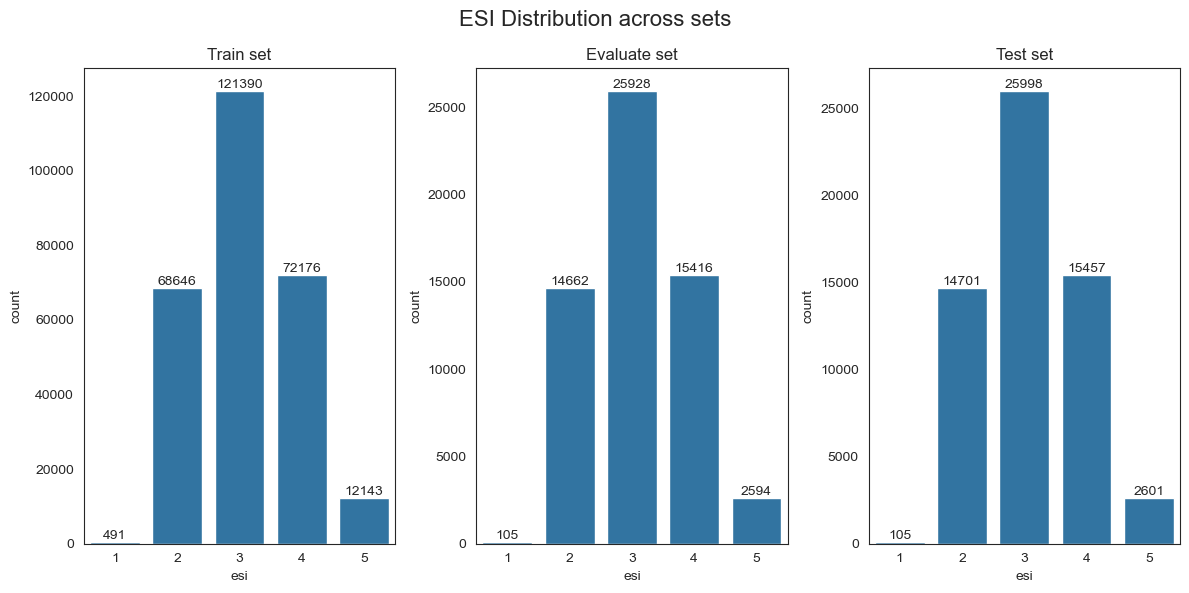

In [6]:
#Plotting histograms to show target feature distribution across sets
#evidence for correct stratification
#value counts added to show ESI level 1 instances.

fig, axes = plt.subplots(1,3, figsize = (12,6))
sns.set_style('white')
plot1 = axes[0]
plot2 = axes[1]
plot3 = axes[2]

chart1 = sns.countplot(x =y_train, ax = plot1)
plot1.set_title("Train set")
chart1.bar_label(chart1.containers[0]) #add value counts to bars

chart2 = sns.countplot(x = y_val, ax = plot2)
plot2.set_title("Evaluate set")
chart2.bar_label(chart2.containers[0])

chart3 = sns.countplot(x = y_test, ax = plot3)
plot3.set_title("Test set")
chart3.bar_label(chart3.containers[0])

plt.suptitle('ESI Distribution across sets', fontsize = 16)
plt.tight_layout()
plt.show()

## 2. Functions for Model Development and Chart Plotting

In [6]:
#Function to determine the optimal number of estimators for XGBoost
#based on a set learning_rate

def find_optimal_estimators(X, y, learning_rate=0.1, early_stopping_rounds=50):
    
    #Convert data into native DMatrix format required by xgb.cv
    dtrain = xgb.DMatrix(X, label=y)
    
    
    params = {
        'objective': 'multi:softprob',
        'num_class': len(np.unique(y)),
        'learning_rate': learning_rate,
        'max_depth': 6,               # Baseline depth before tuning
        'eval_metric': 'mlogloss',
        'seed': 42
    }
    
    print(f"Running Cross-Validation with early stopping (LR = {learning_rate})")
    
    # Run Cross-Validation
    cv_results = xgb.cv(
        params=params,
        dtrain=dtrain,
        num_boost_round=3000,         # Set a high ceiling
        nfold=5,                      # 5-fold CV
        stratified=True,
        early_stopping_rounds=early_stopping_rounds,
        metrics='mlogloss',
        seed=42,
        as_pandas=True
    )
    
    #Extract the optimal number of rounds
    optimal_estimators = len(cv_results)
    best_logloss = cv_results['test-mlogloss-mean'].min()
    
    print("\n---- Early Stopping Results ----")
    print(f"Optimal n_estimators found: {optimal_estimators}")
    print(f"Best CV Multi-LogLoss: {best_logloss:.4f}")
    
    return optimal_estimators

In [7]:
#function to tune XGBoost model using RandomizedSearchCV and StratifiedKFold
#param_dist = dictionary of hyperparameter distributions
#X = training features y = training target labels
#num_iterations = number of combinations to try

def tune_XGBoost(param_dist, X, y, num_iterations, n_estimators, learning_rate):
    
    #initialiing smote
    #boosting class 1 and class 5
    #Values tested for class 1: 2500, 5000, 10000, 20000
    smote = SMOTE(
        sampling_strategy={0: 5000, 4: 20000}, #no. samples to boost to
        random_state=42
    )
    
    #pipeline smote -> model building
    pipeline = ImbPipeline([
        ('oversample', smote),
        ('xgb', XGBClassifier(
            n_estimators = n_estimators,
            learning_rate = learning_rate,
            random_state = 42
        ))
    ])
    
    #set up 5-fold cross validation strategy
    cv_strategy = StratifiedKFold(n_splits=5,shuffle=True, random_state=42)
    
    #configure RandomizedSearchCV
    random_search = RandomizedSearchCV(
        estimator = pipeline,
        param_distributions=param_dist,
        n_iter=num_iterations,
        cv = cv_strategy,
        scoring = 'f1_macro',
        n_jobs=-2, #use all but 1 cpu cores
        random_state=42,
        verbose=2 #print progress updates
    )
    
    #Fit model
    print("Starting Hyperparameter tuning")
    random_search.fit(X,y)

    #Output best Hyperparameters found
    print("\n---- Results ----")
    print(f"Best Score (F1-macro): {random_search.best_score_:.4f}")
    print("Best Hyperparameters:")
    for param, value in random_search.best_params_.items():
        print(f" - {param}: {value}")
    
    #Return optimised model
    best_model = random_search.best_estimator_
    return best_model

In [8]:
#Optimizing model threshold weights
#Aiming to acheive high recall for minority classes while maintaining a good macro-F1 score
#This function prioritises the Class 1 threshold over the Class 5 threshold
#Needs to be passed a Trained Model, Training Features, Target Labels
#Target recalls can be specified if necessary

def threshold_weighting (model, X, y,target_c1_recall=0.55, target_c5_recall=0.50):

    #extract raw prediction probabilities
    val_probs = model.predict_proba(X)
    #set baseline weights
    base_weights = np.array([1.0, 1.0, 1.0, 1.0, 1.0])

    #Optimizing Class 1 multiplier
    
    best_class1_weight = 1.0
    best_class1_f1 = 0.0
    max_c1_recall = 0.0
    fallback_c1_weight = 1.0

    #iterate through potential weights from 1.0 to 50.0
    #testing 100 spaced multipliers
    for c1_w in np.linspace(1.0, 50.0, 100):
        temp_weights = base_weights.copy()
        temp_weights[0] = c1_w 
        
        #calulate predictions and metrics
        preds = np.argmax(val_probs * temp_weights, axis = 1)
        c1_recall = recall_score(y, preds, labels=[0], average=None)[0]
        macro_f1 = f1_score(y, preds, average='macro')

        
        if c1_recall > max_c1_recall:
            max_c1_recall = c1_recall
            fallback_c1_weight = c1_w
        
        #check if class 1 recall greater than threshold
        if c1_recall >= target_c1_recall:
            if macro_f1 > best_class1_f1:
                best_class1_f1 = macro_f1
                best_class1_weight = c1_w
    
    if best_class1_f1 == 0.0:
        best_class1_weight = fallback_c1_weight
        print(f"[Warning] Class 1 target recall ({target_c1_recall}) not met. Fallback weight: {best_class1_weight:.2f} (Recall: {max_c1_recall:.2f})")
    
    #optimizing Class 5 Multiplier

    #update base_weights with class 1 multiplier
    base_weights[0] = best_class1_weight
    best_class5_weight = 1.0
    best_class5_f1 = 0.0
    max_c5_recall = 0.0
    fallback_c5_weight = 1.0

    for c5_w in np.linspace(1.0, 50.0, 100):
        temp_weights = base_weights.copy()
        temp_weights[4] = c5_w 

        preds = np.argmax(val_probs * temp_weights, axis = 1)
        c5_recall = recall_score(y, preds, labels=[4], average=None)[0]
        macro_f1 = f1_score(y, preds, average='macro')

        if c5_recall > max_c5_recall:
            max_c5_recall = c5_recall
            fallback_c5_weight = c5_w

        #check if class 5 recall greater than threshold
        if c5_recall >= target_c5_recall:
            if macro_f1 > best_class5_f1:
                best_class5_f1 = macro_f1
                best_class5_weight = c5_w

    if best_class5_f1 == 0.0:
        best_class5_weight = fallback_c5_weight
        print(f"[Warning] Class 5 target recall ({target_c5_recall}) not met. Fallback weight: {best_class5_weight:.2f} (Recall: {max_c5_recall:.2f})")
                
    #Produce final weights Array
    final_weights = np.array([best_class1_weight, 1.0, 1.0, 1.0, best_class5_weight])
    #Output weights
    print("--- final weight multipliers ---")
    for i, w in enumerate(final_weights):
        print(f"Class {i+1} Multiplier: {w:.2f}")
    #returns the weight multipliers
    return final_weights, val_probs

In [9]:
#function to tune Random Forest model using RandomizedSearchCV and StratifiedKFold
#param_dist = dictionary of hyperparameter distributions
#X = training features y = training target labels
#num_iterations = number of combinations to try


def tune_rForest(param_dist, X, y, num_iterations):
    
    #initialiing smote
    #boosting class 1 and class 5
    #Values tested for class 1: 2500, 5000, 10000, 20000
    smote = SMOTE(
        sampling_strategy={0: 5000, 4: 20000}, #no. samples to boost to
        random_state=42
    )
    
    #pipeline smote -> model building
    pipeline = ImbPipeline([
        ('oversample', smote),
        ('rf', RandomForestClassifier(
            random_state = 42,
            n_jobs = -1
        ))
    ])
    
    #set up 5-fold cross validation strategy
    cv_strategy = StratifiedKFold(n_splits=5,shuffle=True, random_state=42)
    
    #configure RandomizedSearchCV
    random_search = RandomizedSearchCV(
        estimator = pipeline,
        param_distributions=param_dist,
        n_iter=num_iterations,
        cv = cv_strategy,
        scoring = 'f1_macro',
        n_jobs=-2, #use all but 1 cpu cores
        random_state=42,
        verbose=2 #print progress updates
    )
    
    #Fit model
    print("Starting Hyperparameter tuning")
    random_search.fit(X,y)

    #Output best Hyperparameters found
    print("\n---- Results ----")
    print(f"Best Score (F1-macro): {random_search.best_score_:.4f}")
    print("Best Hyperparameters:")
    for param, value in random_search.best_params_.items():
        print(f" - {param}: {value}")
    
    #Return optimised model
    return random_search.best_estimator_

In [10]:
#function to tune K-NN model using RandomizedSearchCV and StratifiedKFold
#param_dist = dictionary of hyperparameter distributions
#X = training features y = training target labels
#num_iterations = number of combinations to try


def tune_knn(param_dist, X, y, num_iterations):
    
    #initialiing smote
    #boosting class 1 and class 5
    #Values tested for class 1: 2500, 5000, 10000, 20000
    smote = SMOTE(
        sampling_strategy={0: 5000, 4: 20000}, #no. samples to boost to
        random_state=42
    )
    
    #pipeline smote -> model building
    pipeline = ImbPipeline([
        ('oversample', smote),
        ('scaler', StandardScaler()), #KNN Requires scaled features
        ('knn', KNeighborsClassifier(
            n_jobs = -2
        ))
    ])
    
    #set up 5-fold cross validation strategy
    cv_strategy = StratifiedKFold(n_splits=5,shuffle=True, random_state=42)
    
    #configure RandomizedSearchCV
    random_search = RandomizedSearchCV(
        estimator = pipeline,
        param_distributions=param_dist,
        n_iter=num_iterations,
        cv = cv_strategy,
        scoring = 'f1_macro',
        n_jobs=-2, #use all but 1 cpu cores
        random_state=42,
        verbose=2 #print progress updates
    )
    
    #Fit model
    print("Starting Hyperparameter tuning")
    random_search.fit(X,y)

    #Output best Hyperparameters found
    print("\n---- Results ----")
    print(f"Best Score (F1-macro): {random_search.best_score_:.4f}")
    print("Best Hyperparameters:")
    for param, value in random_search.best_params_.items():
        print(f" - {param}: {value}")
    
    #Return optimised model
    return random_search.best_estimator_

In [ ]:
#Note:
#Both ROC and P/R plotting functions require label_binarizer to be declared outside the functions
#Due to y_train variations e.g. LLM Boosted or non-PMH
#e.g. label_binarizer = LabelBinarizer().fit(y_train_encoded)

In [11]:
#Function for plotting ROC-AUC curve for single model
#Takes as inputs:
#modelName a string to be used in the plot title e.g. "XGBoost V1"
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_score which is the models predicted y value probas e.g. my_pred_probas
#Returns:
#A plot showing ROC curves for each ESI class and a macro-avg curve


def PlotROC_oneModel(modelName, y_test, y_score):

    #Assign ESI code to each class value
    class_names = { 
        0:"ESI 1",
        1:"ESI 2",
        2:"ESI 3",
        3:"ESI 4",
        4:"ESI 5"
    }
    #One-hot encode y_test
    y_onehot_test = label_binarizer.transform(y_test)

    #calculate individual ROC curves for each of the 5 ESI levels
    fpr, tpr, roc_auc = dict(), dict(), dict()
    for i in range(5):
        fpr[i], tpr[i], _ = roc_curve(y_onehot_test[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    #calculate Macro-avg ROC-AUC
    fpr_grid = np.linspace(0.0,1.0,1000)
    mean_tpr = np.zeros_like(fpr_grid)

    for i in range(5):
        mean_tpr += np.interp(fpr_grid, fpr[i], tpr[i])

    #Average it and Compute AUC
    mean_tpr /= 5
    fpr['macro'] = fpr_grid
    tpr['macro'] = mean_tpr
    roc_auc['macro'] = auc(fpr['macro'], tpr['macro'])

    #Plotting
    fig, ax = plt.subplots(figsize = (8,8))

    #plotting the avg curve
    plt.plot(
        fpr['macro'],
        tpr['macro'],
        label = f"Macro-Avg (AUC = {roc_auc['macro']:.2f})",
        color = 'black',
        linestyle = '--',
        linewidth = 2
    )

    #Plotting each ESI score curve
    colors = cycle(['lightblue','darkorange','navy','brown','green'])
    for class_id, color in zip(range(5), colors):
        RocCurveDisplay.from_predictions(
            y_onehot_test[:, class_id],
            y_score[:, class_id],
            name = class_names[class_id],
            ax = ax,
            plot_chance_level = (class_id == 4), #4 for final class, put it last in legend
            despine = True,
            color = color
        )
    #Formatting Titles and Labels:
    _ = ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title =f"ROC Curve for {modelName} (One-vs-Rest)"
    )
    plt.legend(loc='lower right')
    plt.show()

In [12]:
#Function for plotting ROC-AUC curve for multiple models
#Inputs:
#modelNames a list of model names to be used in the plot legend
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_scores a list of y_score which is the models' predicted y value probas e.g. my_pred_probas[0-4]
#
#Returns:
#A single plot showing macro-avg ROC curves for each model provided.

def PlotROC_multiModel(modelNames, y_test, y_scores):

    #one-hot encoding y_test
    y_onehot_test = label_binarizer.transform(y_test)

    #plot setup
    fig, ax = plt.subplots(figsize=(8,8))
    colors = cycle(['lightblue','blue','darkorange','green','purple', 'red'])

    #looping through each model
    #calculating and plotting macro-avg ROC
    for modelName, y_score, color in zip(modelNames, y_scores, colors):

        #calculate individual ROC curves for each of the 5 ESI levels
        fpr, tpr, roc_auc = dict(), dict(), dict()
        for i in range(5):
            fpr[i], tpr[i], _ = roc_curve(y_onehot_test[:, i], y_score[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])

        #calculate Macro-avg ROC-AUC
        fpr_grid = np.linspace(0.0,1.0,1000)
        mean_tpr = np.zeros_like(fpr_grid)
       
        for i in range(5):
            mean_tpr += np.interp(fpr_grid, fpr[i], tpr[i])

        #Average it and Compute AUC
        mean_tpr /= 5
        fpr['macro'] = fpr_grid
        tpr['macro'] = mean_tpr
        roc_auc['macro'] = auc(fpr['macro'], tpr['macro'])
       
        #plotting the avg curve for current model
        plt.plot(
            fpr['macro'],
            tpr['macro'],
            label = f"{modelName} Macro-Average (AUC = {roc_auc['macro']:.2f})",
            color = color,
            linewidth = 2,
        )

    #plot chance level
    plt.plot([0,1],[0,1], 'k--', label="Chance Level (AUC = 0.50)")

    #Formatting Titles and labels etc:
    _ = ax.set(
        xlabel = "False Positive Rate",
        ylabel = "True Positive Rate",
        title = "Macro-Average ROC Curves across Multiple Models (One-vs-Rest)",
        xlim = [-0.01, 1.0], #matching RocCurveDisplay defaults
        ylim = [-0.01, 1.0]
    )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.legend(loc='lower right')
    plt.show()

In [13]:
#Function for plotting Precision Recall curve for single model
#Takes as inputs:
#modelName a string to be used in the plot title e.g. "XGBoost V1"
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_score which is the models predicted y value probas e.g. my_pred_probas
#Returns:
#A plot showing PRecision Recall curves for each ESI class and a macro-avg curve

def PlotPR_oneModel(modelName, y_test, y_score):

     #Assign ESI code to each class value
    class_names = { 
        0:"ESI 1",
        1:"ESI 2",
        2:"ESI 3",
        3:"ESI 4",
        4:"ESI 5"
    }
    #One-hot encode y_test
    y_onehot_test = label_binarizer.transform(y_test)

    #Calculate individual PR curves for each of the 5 ESI levels
    precision, recall, average_precision = dict(), dict(), dict()
    for i in range(5):
        precision[i], recall[i], _ = precision_recall_curve(y_onehot_test[:, i], y_score[:, i])
        average_precision[i] = average_precision_score(y_onehot_test[:, i], y_score[:, i])

    #Calculate Macro-avg PR
    recall_grid = np.linspace(0.0, 1.0, 1000)
    mean_precision = np.zeros_like(recall_grid)

    for i in range(5):
        mean_precision += np.interp(recall_grid,recall[i][::-1], precision[i][::-1])
        #reverse the arrays [::-1] to give ascending X-values to np.interp

    #average it and compute PR
    mean_precision /= 5
    recall['macro'] = recall_grid
    precision['macro'] = mean_precision
    average_precision['macro'] = average_precision_score(y_onehot_test, y_score, average='macro')

    #plotting
    fig, ax = plt.subplots(figsize = (8,8))

    #plotting the avg curve
    display = PrecisionRecallDisplay(
        recall=recall['macro'],
        precision=precision['macro'],
        average_precision=average_precision['macro']
    )
    display.plot(
        ax= ax, 
        name="Macro-Avg Precision-Recall", 
        color = "black"
    )

    #Plotting each ESI score curve
    colors = cycle(['lightblue','darkorange','navy','brown','green'])
    for class_id, color in zip(range(5), colors):
        display = PrecisionRecallDisplay(
            recall=recall[class_id],
            precision=precision[class_id],
            average_precision=average_precision[class_id]
        )
        display.plot(
            ax=ax,
            name=f"Precision-Recall for {class_names[class_id]}",
            color = color,
            despine = True
        )
    #set the legend, title and axes:
    handles,labels = display.ax_.get_legend_handles_labels()
    ax.legend(handles=handles, labels=labels, loc='upper right')
    ax.set_title(f"Precision-Recall Curve for {modelName}")

    plt.show()


In [14]:
#Function for plotting PR curve for multiple models
#Inputs:
#modelNames a list of model names to be used in the plot legend
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_scores a list of y_score which is the models' predicted y value probas e.g. my_pred_probas[0-4]
#
#Returns:
#A single plot showing macro-avg PR curves for each model provided.

def PlotPR_multiModel(modelNames, y_test, y_scores):

    y_onehot_test = label_binarizer.transform(y_test)

    #plot setup
    fig, ax = plt.subplots(figsize=(8,8))
    colors = cycle(['lightblue','blue','darkorange','green','purple', 'red'])

    #looping through each model
    #calculating and plotting the macro-avg PR
    for modelName, y_score, color in zip(modelNames, y_scores, colors):

     #Calculate individual PR curves for each of the 5 ESI levels
        precision, recall, average_precision = dict(), dict(), dict()
        for i in range(5):
            precision[i], recall[i], _ = precision_recall_curve(y_onehot_test[:, i], y_score[:, i])
            average_precision[i] = average_precision_score(y_onehot_test[:, i], y_score[:, i])
     
        #Calculate Macro-avg PR
        recall_grid = np.linspace(0.0, 1.0, 1000)
        mean_precision = np.zeros_like(recall_grid)
     
        for i in range(5):
            mean_precision += np.interp(recall_grid,recall[i][::-1], precision[i][::-1])
            #reverse the arrays [::-1] to give ascending X-values to np.interp
     
        #average it and compute PR
        mean_precision /= 5
        recall['macro'] = recall_grid
        precision['macro'] = mean_precision
        average_precision['macro'] = average_precision_score(y_onehot_test, y_score, average='macro')
     
        #plotting the avg curve
        display = PrecisionRecallDisplay(
            recall=recall['macro'],
            precision=precision['macro'],
            average_precision=average_precision['macro']
        )
        display.plot(
            ax= ax, 
            name=f"Macro-Avg PR for {modelName}", 
            color = color
        )   

    #set the legend, title and axes:
    handles,labels = display.ax_.get_legend_handles_labels()
    ax.legend(handles=handles, labels=labels, loc='upper right')
    ax.set_title(f"Precision-Recall Curve for Multiple Models")

    plt.show()

## 3. Initial Model Training and Hyperparameter Tuning

### Dataset Encoding

In [15]:
#Encoding Chief Complaint using Target Encoding

#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train[['chief_complaint']],y_train_encoded)

#Transform only for validate and test data
#blindly applies the mappings from training data to transform the val/test data
X_val_encoded['chief_complaint'] = encoder.transform(X_val[['chief_complaint']])
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])


In [16]:
#declaring label binariser globally
#all models in this section are trained on the same y_train_encoded
label_binarizer = LabelBinarizer().fit(y_train_encoded)

### XGBoost (And Feature Importance Visuals)

In [17]:
# XGBoost with defaults
xgbDefault = XGBClassifier()

#default hyperparams from XGBoost docs are:
# n_estimators = 100
# max_depth = 6
# learning_rate=0.3
# objective='multi:softprob'
# subsample = 1
# colsample_bytree = 1
# tree_method = auto

xgbDefault.fit(X_train_encoded,y_train_encoded)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [18]:
#Testing on validation set
#reversing the encoding to represent ESI 1-5
xgbDefault_preds = le.inverse_transform(xgbDefault.predict(X_val_encoded))

#encoded preds proba (used for ROC-AUC curves):
xgb_default_preds = xgbDefault.predict_proba(X_val_encoded)

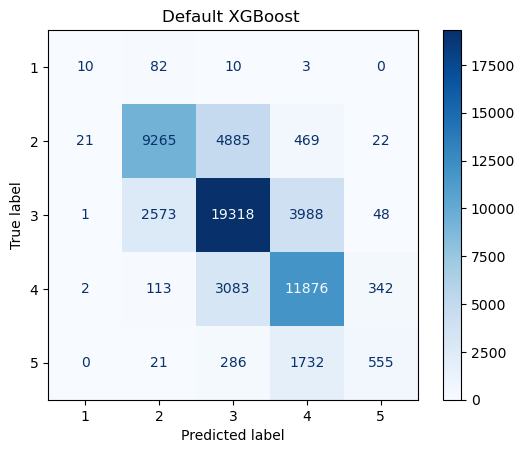

Classification Report:
               precision    recall  f1-score   support

           1       0.29      0.10      0.14       105
           2       0.77      0.63      0.69     14662
           3       0.70      0.75      0.72     25928
           4       0.66      0.77      0.71     15416
           5       0.57      0.21      0.31      2594

    accuracy                           0.70     58705
   macro avg       0.60      0.49      0.52     58705
weighted avg       0.70      0.70      0.69     58705



In [19]:
#Evaluation Metrics:

cm = confusion_matrix(y_val,xgbDefault_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Default XGBoost ")
plt.show()

print("Classification Report:\n", classification_report(y_val,xgbDefault_preds))

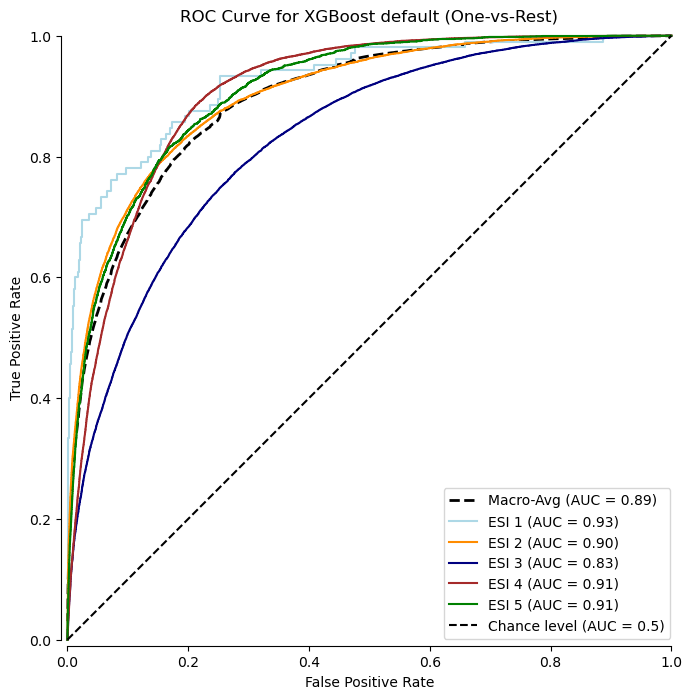

In [20]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="XGBoost default",
                 y_test = y_val_encoded,
                 y_score = xgb_default_preds)

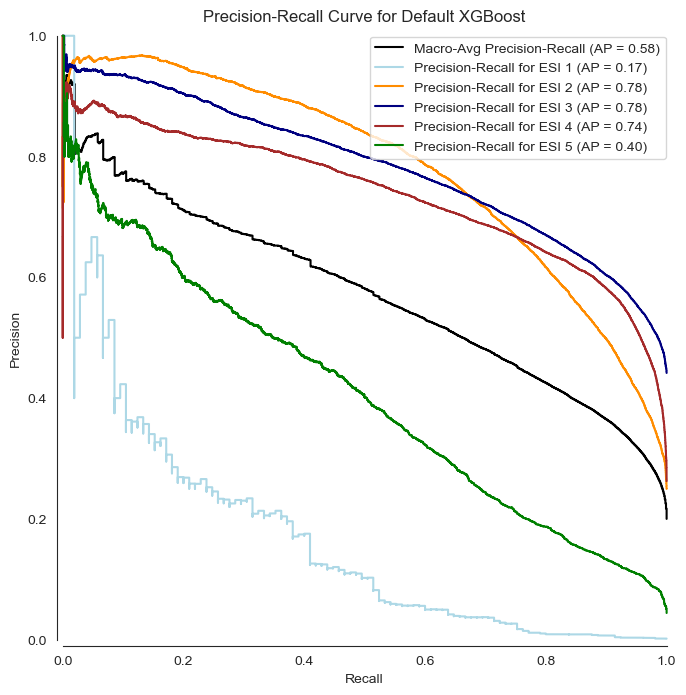

In [162]:
PlotPR_oneModel(
    modelName="Default XGBoost",
    y_test = y_val_encoded,
    y_score=xgb_default_preds
)

#### Plotting Feature Importance

<Axes: title={'center': '40 Most Important Features'}, xlabel='Information gain'>

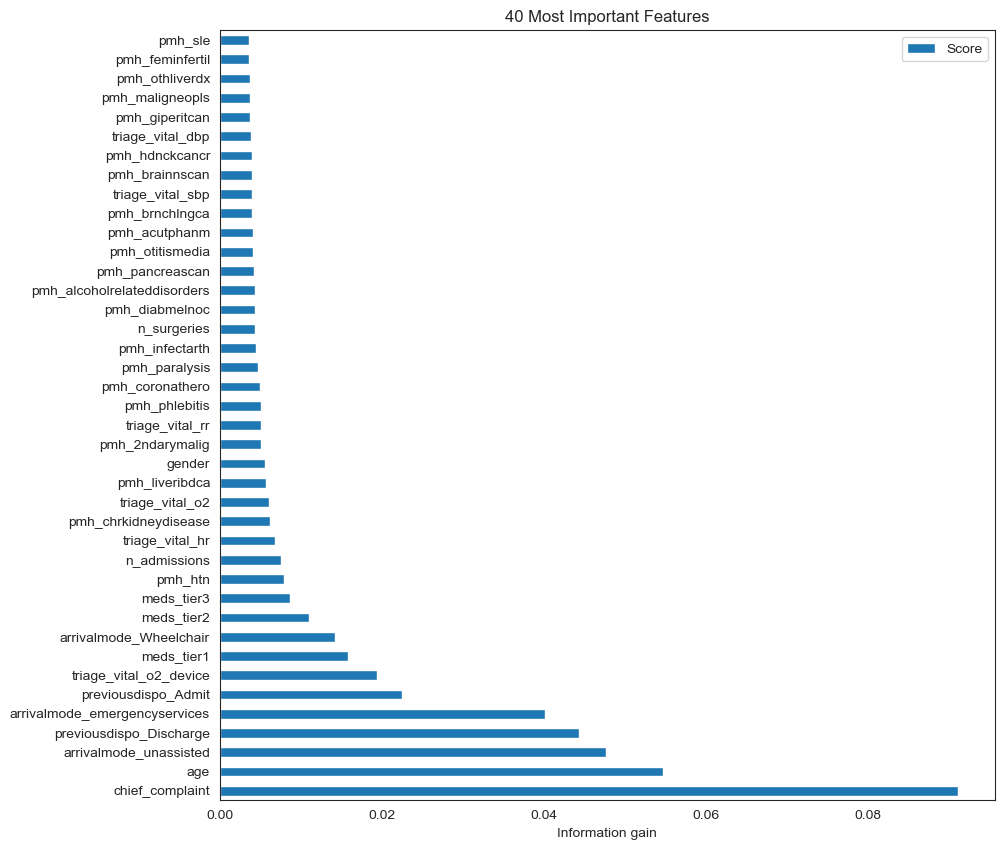

In [17]:
#measuring feature importance based on gain
#Gain-based importance measures the improvement in accuracy brought by a feature to the splits it creates in the trees.
all_features = triage_df.columns.values.tolist()
training_features = all_features.remove('esi')

data = pd.DataFrame({
    'Score': xgbDefault.feature_importances_
}, index=all_features)

#plotting features with largest gain
data = data.sort_values(by='Score', ascending=False)
data.nlargest(40, columns='Score').plot(kind='barh', figsize=(10, 10),
                                        title = "40 Most Important Features", 
                                        xlabel= "Information gain")



#### Hyperparameter Tuning XGBoost using K-fold Cross-validation

In [156]:
optimal_estimators = find_optimal_estimators(
    X = X_train_encoded,
    y=y_train_encoded,
    learning_rate=0.1
)

Running Cross-Validation with early stopping (LR = 0.1)

---- Early Stopping Results ----
Optimal n_estimators found: 555
Best CV Multi-LogLoss: 0.7124


In [20]:
# Running hyperparameter tuning function

# First Round (num_iterations = 20):
# xgb_structure_params = {
#     'xgb__max_depth': [2,4,5,6,7,8,10],
#     'xgb__min_child_weight': [1,3,5,7,9],
#     'xgb__subsample':[0.3,0.5,0.7,0.8,0.9],
#     'xgb__colsample_bytree':[0.3,0.4,0.5,0.6,0.7],
#     'xgb__reg_alpha':[0,1,2,3,4,5],
#     'xgb__reg_lambda':[0,1,3,5,7,9]
# }

# Second Round (num_iterations = 10):
# xgb_structure_params = {
#     'xgb__max_depth': [6],
#     'xgb__min_child_weight': [4,5,6],
#     'xgb__subsample':[0.7,0.8,0.9],
#     'xgb__colsample_bytree':[0.6],
#     'xgb__reg_alpha':[0,1,2,3,4,5],
#     'xgb__reg_lambda':[0,1,3,5,7,9]
# }

#final Hyperparameters:
xgb_structure_params = {
    'xgb__max_depth': [6],
    'xgb__min_child_weight': [5],
    'xgb__subsample':[0.7],
    'xgb__colsample_bytree':[0.6],
    'xgb__reg_alpha':[1],
    'xgb__reg_lambda':[3]
}
tuned_xgb = tune_XGBoost(
    param_dist=xgb_structure_params,
    X = X_train_encoded,
    y = y_train_encoded,
    num_iterations=1,
    n_estimators=555, #taken from optimal estimators func
    learning_rate=0.1
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 1 candidates, totalling 5 fits

---- Results ----
Best Score (F1-macro): 0.5405
Best Hyperparameters:
 - xgb__subsample: 0.7
 - xgb__reg_lambda: 3
 - xgb__reg_alpha: 1
 - xgb__min_child_weight: 5
 - xgb__max_depth: 6
 - xgb__colsample_bytree: 0.6


In [21]:
#Applying threshold weighting
#aiming for 0.60 Recall for ESI 1
final_weights, val_probs = threshold_weighting(tuned_xgb,X_val_encoded,y_val_encoded,
                                               target_c1_recall=0.6)

#applying threshold multipliers to predictions
optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
xgb_tuned_weighted_1 = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 40.10
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 2.98


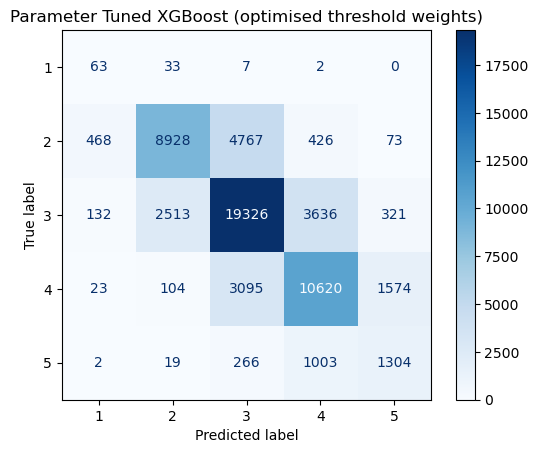

Classification Report:
               precision    recall  f1-score   support

           1       0.09      0.60      0.16       105
           2       0.77      0.61      0.68     14662
           3       0.70      0.75      0.72     25928
           4       0.68      0.69      0.68     15416
           5       0.40      0.50      0.44      2594

    accuracy                           0.69     58705
   macro avg       0.53      0.63      0.54     58705
weighted avg       0.70      0.69      0.69     58705



In [22]:
#Model evaluation with tuned hyperparameters:

#Testing on validation set
#reversing the encoding to represent ESI 1-5
xgb_preds = le.inverse_transform(tuned_xgb.predict(X_val_encoded))

cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Parameter Tuned XGBoost (optimised threshold weights)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))


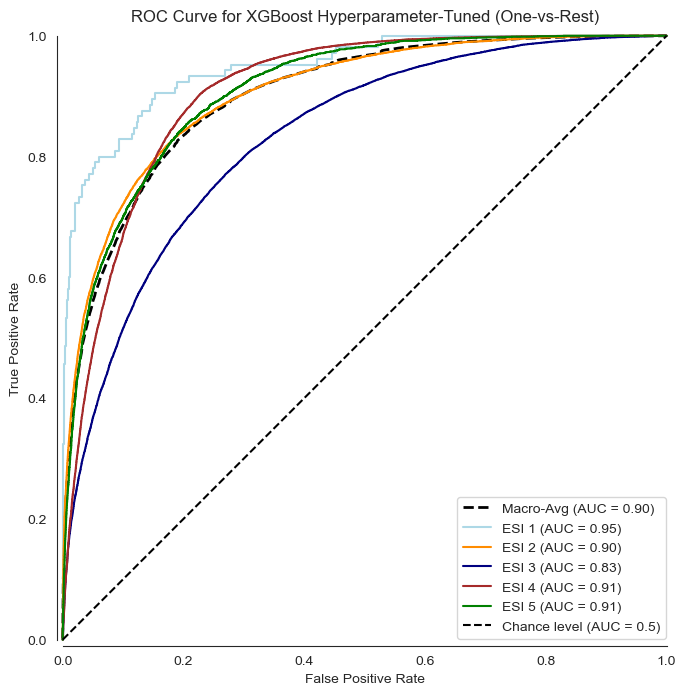

In [213]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="XGBoost Hyperparameter-Tuned",
                 y_test = y_val_encoded,
                 y_score = xgb_tuned_weighted_1)

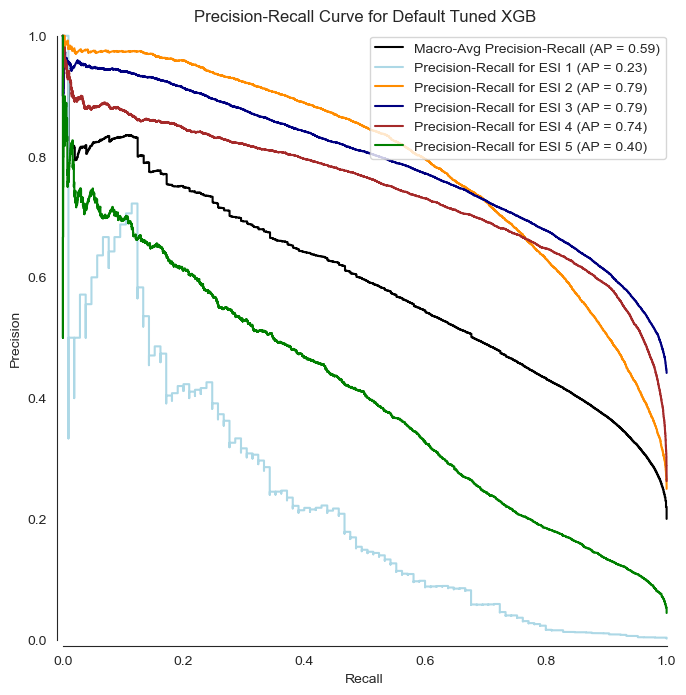

In [214]:
PlotPR_oneModel(
    modelName="Default Tuned XGB",
    y_test = y_val_encoded,
    y_score=xgb_tuned_weighted_1
)

### Random Forest

In [21]:
# Default Random Forest 
rfDefault = RandomForestClassifier()
#default hyperparams:
# n_estimators = 100
# criterion = 'gini'
# max_depth = None
# min_samples_split = 2
# min_samples_leaf = 1
# min_weight_fraction_leaf = 0.0
# max_features = 'sqrt'
# max_leaf_nodes = None
# min_impurity_decrease = 0.0
# bootstrap = True
# oob_score = False
# n_jobs = None
# random_state = None
# verbose = 0
# warm_start = False
# class_weight = None
# max_samples = None

#Fitting default RF on small train set
rfDefault.fit(X_train_encoded,y_train_encoded)


RandomForestClassifier()

In [22]:
#Testing on small validation set
#reversing the encoding to represent ESI 1-5
rfDefault_preds = le.inverse_transform(rfDefault.predict(X_val_encoded))

#encoded preds proba (used for ROC-AUC curves):
rf_default_preds = rfDefault.predict_proba(X_val_encoded)

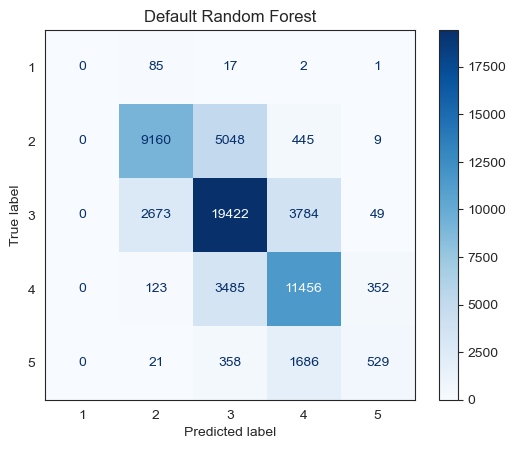

c:\Users\paddy\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\paddy\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Classification Report:
               precision    recall  f1-score   support

           1       0.00      0.00      0.00       105
           2       0.76      0.62      0.69     14662
           3       0.69      0.75      0.72     25928
           4       0.66      0.74      0.70     15416
           5       0.56      0.20      0.30      2594

    accuracy                           0.69     58705
   macro avg       0.53      0.46      0.48     58705
weighted avg       0.69      0.69      0.68     58705



c:\Users\paddy\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [165]:
#Evaluation Metrics:

cm = confusion_matrix(y_val,rfDefault_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Default Random Forest")
plt.show()

print("Classification Report:\n", classification_report(y_val,rfDefault_preds))

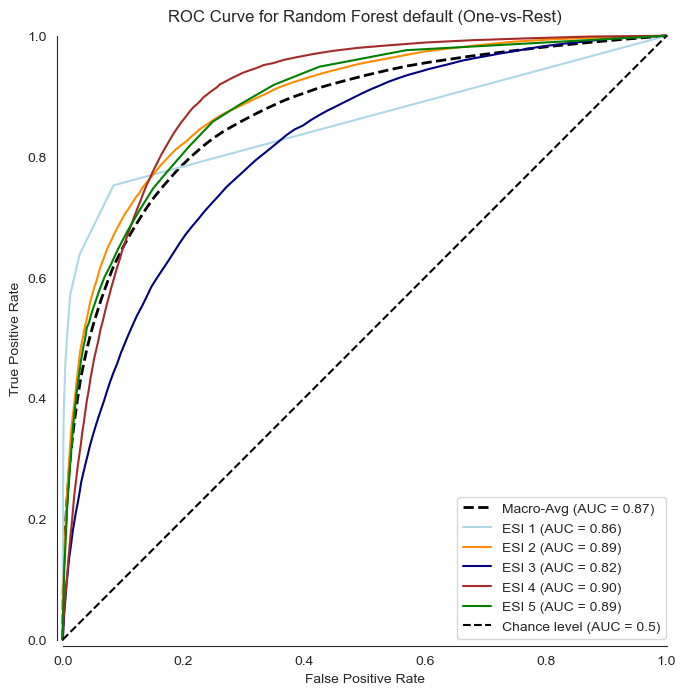

In [166]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="Random Forest default",
                 y_test = y_val_encoded,
                 y_score = rf_default_preds)

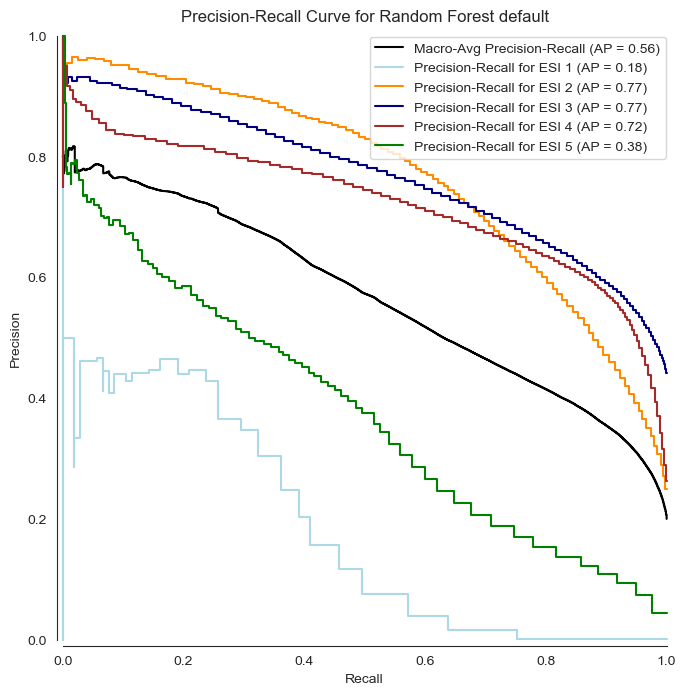

In [167]:
#Plotting PR Curve
PlotPR_oneModel(modelName="Random Forest default",
                 y_test = y_val_encoded,
                 y_score = rf_default_preds)

#### Hyperparameter Tuning Random Forest using K-fold Cross-validation

In [17]:
#Running hyperparameter tuning function

#First Round (Num_iterations = 20):
# rf_structure_params = {
#      'rf__n_estimators': [50, 100, 150, 250, 500],
#      'rf__criterion': ['gini','entropy','log_loss'],
#      'rf__max_depth': [None, 10, 20, 30, 50],
#      'rf__min_samples_split': [2, 5, 10, 20, 40],
#      'rf__min_samples_leaf': [1, 2, 4, 10, 20],
#      'rf__max_features': ['sqrt','log2']
# }

#Second Roun (num_iterations = 10):
# rf_structure_params = {
#      'rf__n_estimators': [125, 140, 150, 160, 175],
#      'rf__criterion': ['gini','entropy','log_loss'],
#      'rf__max_depth': [None],
#      'rf__min_samples_split': [12, 15, 17, 20],
#      'rf__min_samples_leaf': [1, 2, 4],
#      'rf__max_features': ['sqrt','log2']
# }

#Final hyperparameters:
rf_structure_params = {
    'rf__n_estimators': [125],
    'rf__criterion': ['gini'],
    'rf__max_depth': [None],
    'rf__min_samples_split': [20],
    'rf__min_samples_leaf': [1],
    'rf__max_features': ['sqrt']
}
tuned_rf = tune_rForest(
    param_dist=rf_structure_params,
    X = X_train_encoded,
    y = y_train_encoded,
    num_iterations= 1, 
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 1 candidates, totalling 5 fits

---- Results ----
Best Score (F1-macro): 0.4685
Best Hyperparameters:
 - rf__n_estimators: 125
 - rf__min_samples_split: 20
 - rf__min_samples_leaf: 1
 - rf__max_features: sqrt
 - rf__max_depth: None
 - rf__criterion: gini


In [18]:
#Applying threshold weighting function
#determining "best" class weight multipliers
#aiming for 0.60 Recall for ESI 1
final_weights, val_probs = threshold_weighting(tuned_rf,X_val_encoded,y_val_encoded,
                                               target_c1_recall=0.6)

#applying threshold multipliers to predictions
optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
rf_tuned_weighted_1 = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 13.37
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 3.47


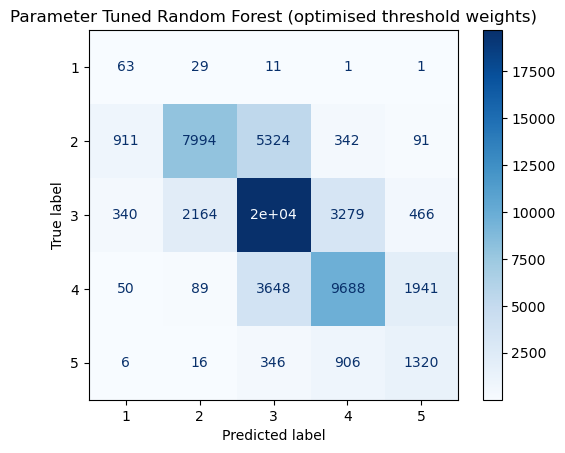

Classification Report:
               precision    recall  f1-score   support

           1       0.05      0.60      0.09       105
           2       0.78      0.55      0.64     14662
           3       0.68      0.76      0.72     25928
           4       0.68      0.63      0.65     15416
           5       0.35      0.51      0.41      2594

    accuracy                           0.66     58705
   macro avg       0.51      0.61      0.50     58705
weighted avg       0.69      0.66      0.67     58705



In [19]:
#Model evaluation with tuned hyperparameters:

#Testing on validation set
#reversing the encoding to represent ESI 1-5
rf_preds = le.inverse_transform(tuned_rf.predict(X_val_encoded))

cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Parameter Tuned Random Forest (optimised threshold weights)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

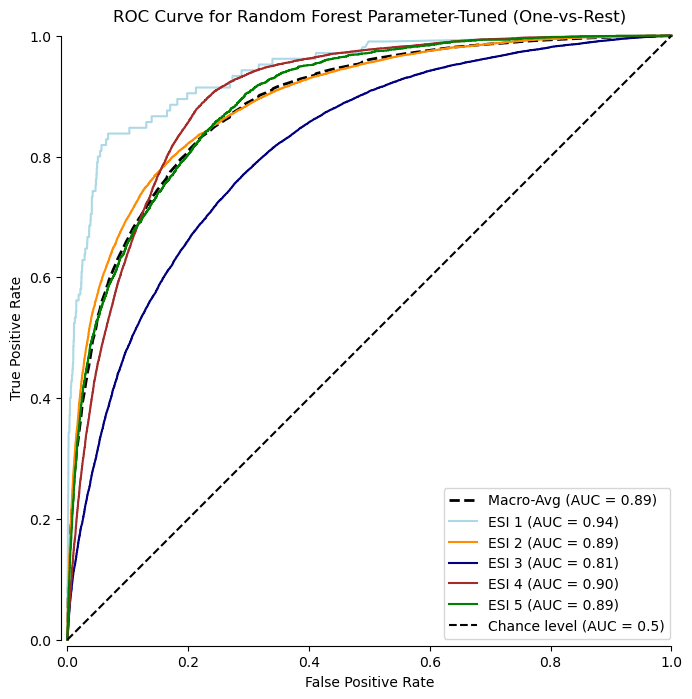

In [23]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="Random Forest Parameter-Tuned",
                 y_test = y_val_encoded,
                 y_score = rf_tuned_weighted_1)

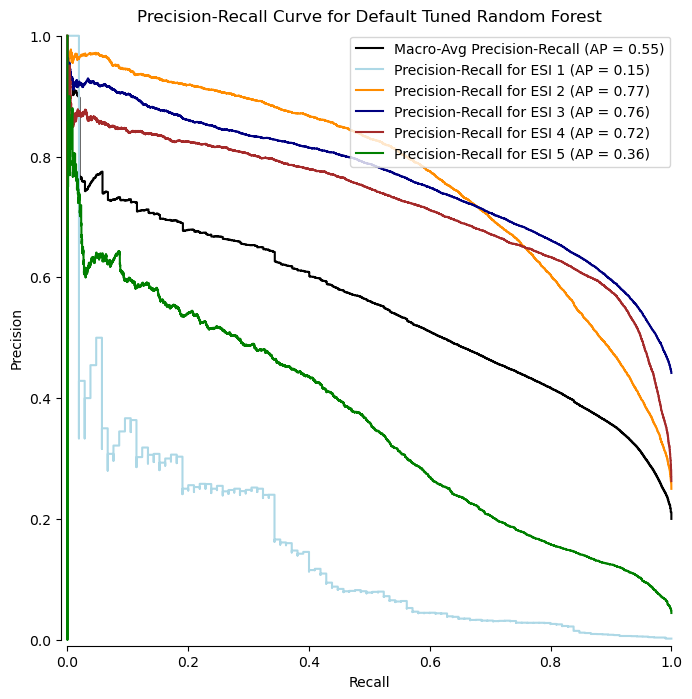

In [24]:
PlotPR_oneModel(
    modelName="Default Tuned Random Forest",
    y_test = y_val_encoded,
    y_score=rf_tuned_weighted_1
)

### K-Nearest Neighbours

In [23]:
#Default KNN
knnDefault = KNeighborsClassifier()
#Default params:
# n_neighbors = 5
# weights = 'uniform'
# algorithm = 'auto'
# leaf_size = 30
# p = 2
# metric = 'minkowski'
# metric_params = None
# n_jobs = None

knnDefault.fit(X_train_encoded,y_train_encoded)

KNeighborsClassifier()

In [24]:
#Testing on small validation set
#reversing the encoding to represent ESI 1-5
knnDefault_preds = le.inverse_transform(knnDefault.predict(X_val_encoded))

#encoded preds proba (used for ROC-AUC curves):
knn_default_preds = knnDefault.predict_proba(X_val_encoded)

c:\Users\paddy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\paddy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\paddy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\paddy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

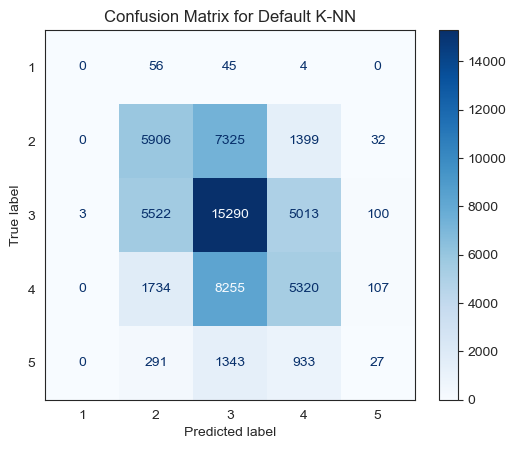

Classification Report:
               precision    recall  f1-score   support

           1       0.00      0.00      0.00       105
           2       0.44      0.40      0.42     14662
           3       0.47      0.59      0.53     25928
           4       0.42      0.35      0.38     15416
           5       0.10      0.01      0.02      2594

    accuracy                           0.45     58705
   macro avg       0.29      0.27      0.27     58705
weighted avg       0.43      0.45      0.44     58705



In [170]:
#Evaluation Metrics:

cm = confusion_matrix(y_val,knnDefault_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix for Default K-NN")
plt.show()

print("Classification Report:\n", classification_report(y_val,knnDefault_preds))

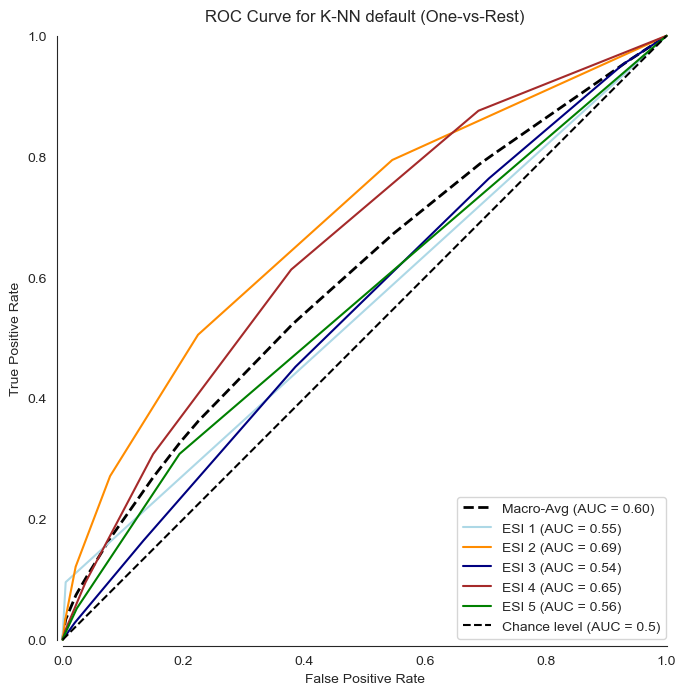

In [171]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="K-NN default",
                 y_test = y_val_encoded,
                 y_score = knn_default_preds)

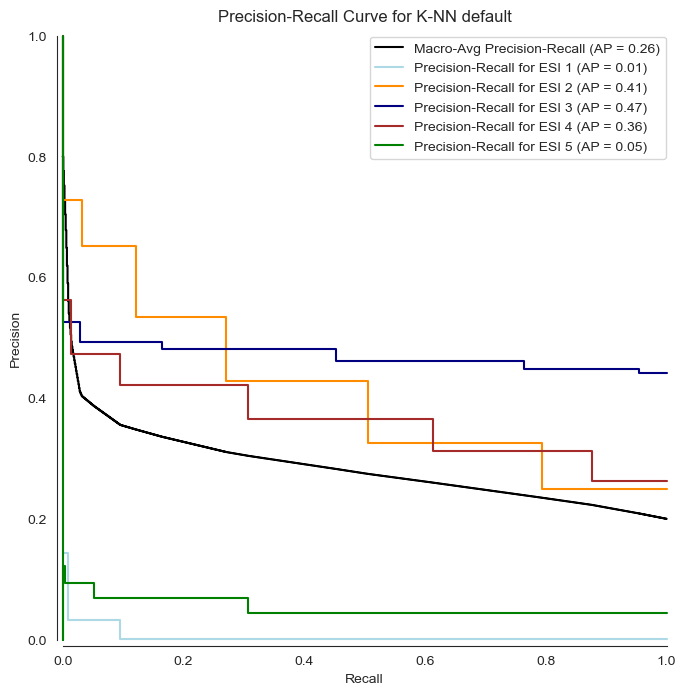

In [172]:
#Plotting PR Curve
PlotPR_oneModel(modelName="K-NN default",
                 y_test = y_val_encoded,
                 y_score = knn_default_preds)

#### Hyperparameter Tuning KNN

In [ ]:
#Running hyperparameter tuning function

#First Round:
# knn_structure_params = {
#     'knn__n_neighbors': [5,11,15,21,31],
#     'knn__weights': ['uniform','distance'],
#     'knn__metric': ['euclidean','manhattan']

# }


# Second Round:
# knn_structure_params = {
#      'knn__n_neighbors': [17,19,21,23,25],
#      'knn__weights': ['distance'],
#      'knn__metric': ['manhattan']
#  }

#Final hyperparameters:
knn_structure_params = {
      'knn__n_neighbors': [23],
      'knn__weights': ['distance'],
     'knn__metric': ['manhattan']
  }
    
tuned_knn = tune_knn(
    param_dist=knn_structure_params,
    X = X_train_encoded,
    y = y_train_encoded,
    num_iterations= 1, #1 run for final params
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 5 candidates, totalling 25 fits


c:\Users\paddy\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



---- Results ----
Best Score (F1-macro): 0.3946
Best Hyperparameters:
 - knn__weights: distance
 - knn__n_neighbors: 23
 - knn__metric: manhattan


In [ ]:
#Applying threshold weighting function
#left to target default ESI 1 recall of 0.55
final_weights, val_probs = threshold_weighting(tuned_knn,X_val_encoded,y_val_encoded)

#applying threshold multipliers to predictions
optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
knn_tuned_weighted_1 = optimised_val_probs

[Warning] Class 1 target recall (0.55) not met. Fallback weight: 21.29 (Recall: 0.20)
--- final weight multipliers ---
Class 1 Multiplier: 21.29
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 5.45


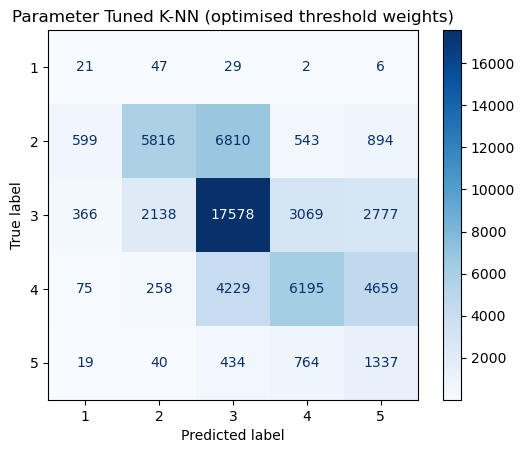

Classification Report:
               precision    recall  f1-score   support

           1       0.02      0.20      0.04       105
           2       0.70      0.40      0.51     14662
           3       0.60      0.68      0.64     25928
           4       0.59      0.40      0.48     15416
           5       0.14      0.52      0.22      2594

    accuracy                           0.53     58705
   macro avg       0.41      0.44      0.38     58705
weighted avg       0.60      0.53      0.54     58705



In [17]:
#Model evaluation with tuned hyperparameters:

#Testing on validation set
#reversing the encoding to represent ESI 1-5
#rf_preds = le.inverse_transform(tuned_knn.predict(X_val_encoded))

cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Parameter Tuned K-NN (optimised threshold weights)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

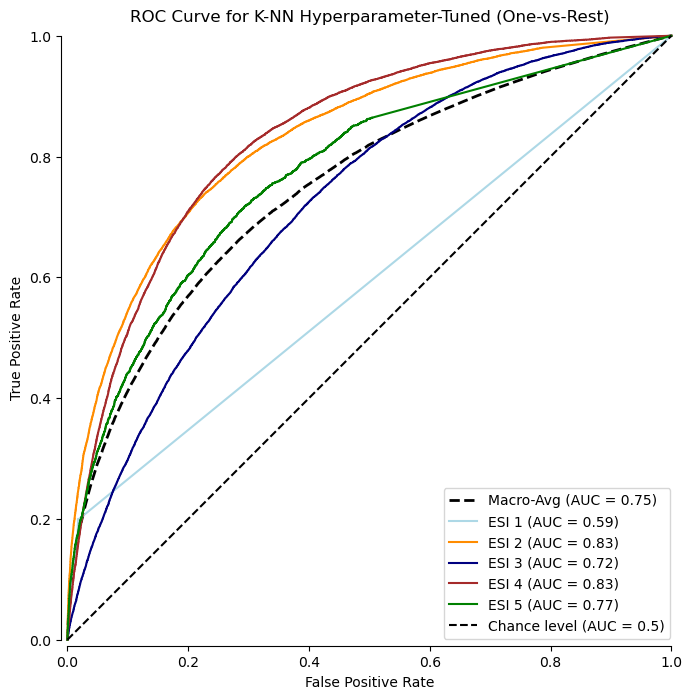

In [18]:
#Plotting ROC-AUC Curve
PlotROC_oneModel(modelName="K-NN Hyperparameter-Tuned",
                 y_test = y_val_encoded,
                 y_score = knn_tuned_weighted_1)

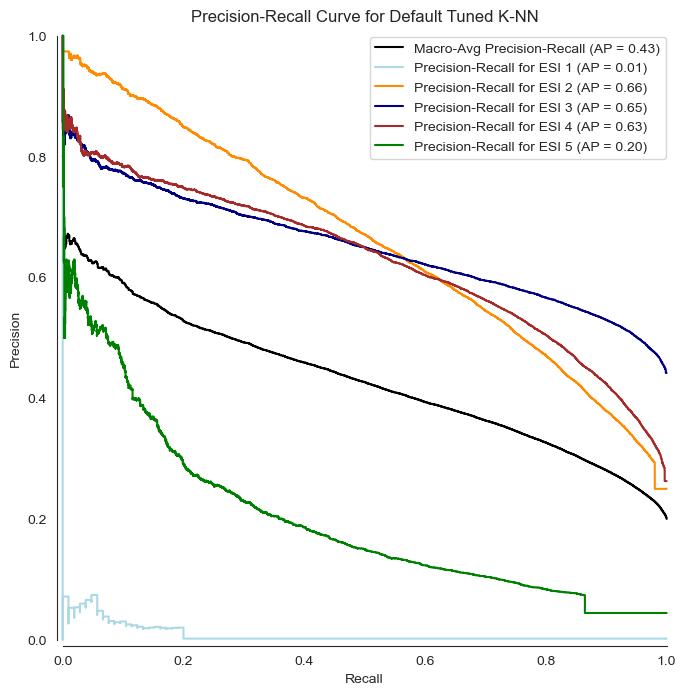

In [ ]:
PlotPR_oneModel(
    modelName="Default Tuned K-NN",
    y_test = y_val_encoded,
    y_score=knn_tuned_weighted_1
)

### Comparison of all 3 default and tuned models

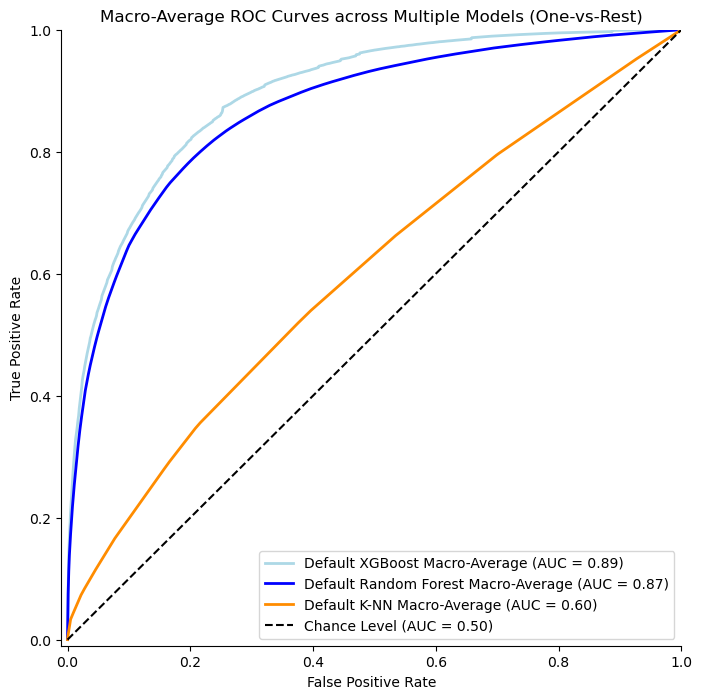

In [25]:
#Plotting Roc curve comparison

PlotROC_multiModel(
    modelNames=['Default XGBoost', 'Default Random Forest', 'Default K-NN'],
    y_test = y_val_encoded,
    y_scores=[xgb_default_preds,rf_default_preds,knn_default_preds]
)

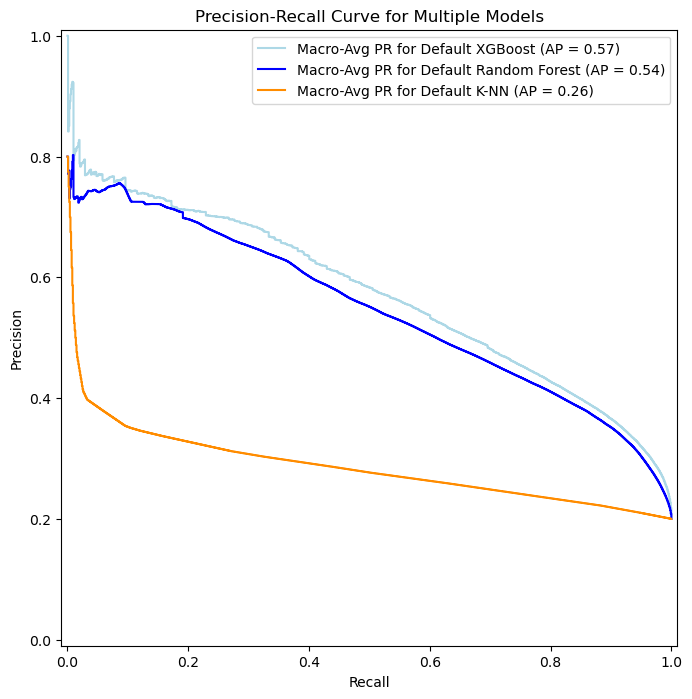

In [26]:
#Plotting PR curve comparison

PlotPR_multiModel(
    modelNames=['Default XGBoost', 'Default Random Forest', 'Default K-NN'],
    y_test = y_val_encoded,
    y_scores=[xgb_default_preds,rf_default_preds,knn_default_preds]
)

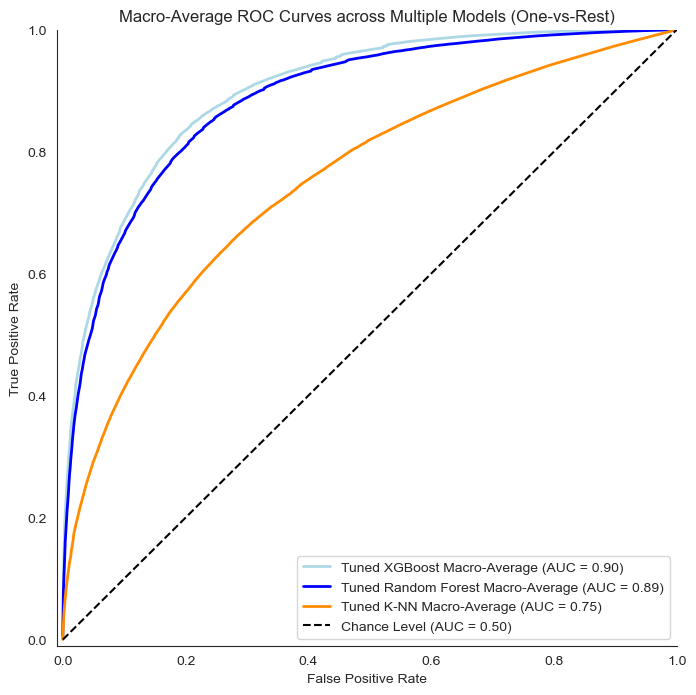

In [219]:
#Plotting Roc curve comparison

PlotROC_multiModel(
    modelNames=['Tuned XGBoost', 'Tuned Random Forest', 'Tuned K-NN'],
    y_test = y_val_encoded,
    y_scores=[xgb_tuned_weighted_1,rf_tuned_weighted_1,knn_tuned_weighted_1]
)

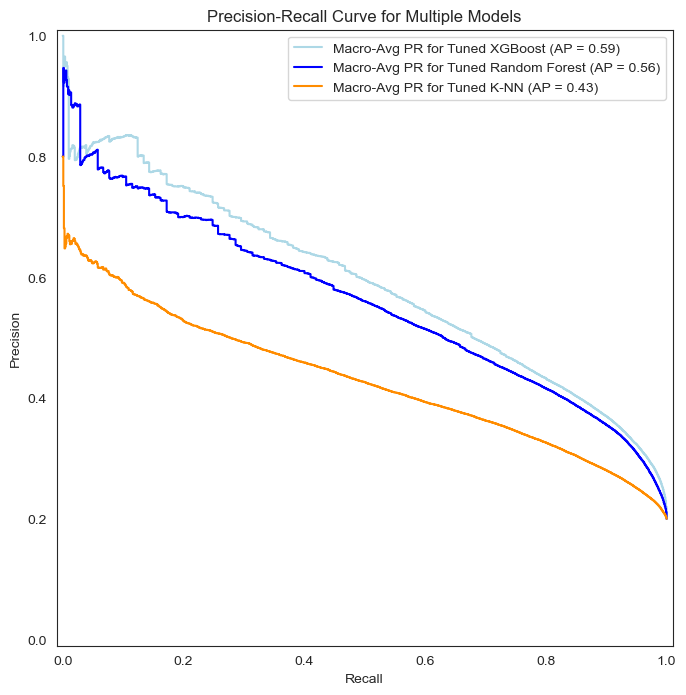

In [220]:
#Plotting PR curve comparison

PlotPR_multiModel(
    modelNames=['Tuned XGBoost', 'Tuned Random Forest', 'Tuned K-NN'],
    y_test = y_val_encoded,
    y_scores=[xgb_tuned_weighted_1,rf_tuned_weighted_1,knn_tuned_weighted_1]
)

## 4. LLM-Boosted Minority Sampling Experiment

Here an LLM is used to produce synthetic ESI 1 class patient data to hopefully improve model performance for the minority class.

In [7]:
#Returning LLM output
#Outputted synthetic patient data based on the samples provided 

LLM_synthetics_df = pd.read_csv('Data/LLM Synthetic Experiment/LLM Output MASTER.csv')

#Splitting the synthetic set into X and y
X1 = LLM_synthetics_df.drop(columns = 'esi')
y1 = LLM_synthetics_df['esi']


#concatenating the synthetic values to the current train values
X_train_synth = pd.concat([X_train,X1])
y_train_synth = pd.concat([y_train,y1])

#ensure esi series is categorical
y_train_synth = y_train_synth.astype(str)

In [10]:
# Comparing chief_complaint value counts between synthetic set and original ESI 1 cases
LLM_values = LLM_synthetics_df['chief_complaint'].value_counts()
ESI_1_values = class_1_records['chief_complaint'].value_counts()
sample_values = esi_1_sample['chief_complaint'].value_counts()

values_df = pd.concat([LLM_values,ESI_1_values,sample_values], axis = 1)
values_df.columns = ['LLM Synthetics','All ESI 1','Sample ESI 1']
values_df = values_df.reset_index().rename(columns={'index':'chief_complaint'})
values_df = values_df.fillna(0)

#sort by Sample ESI 1 value counts descending and limit to top 35 
values_df = values_df.sort_values(by='Sample ESI 1', ascending=False).head(35)

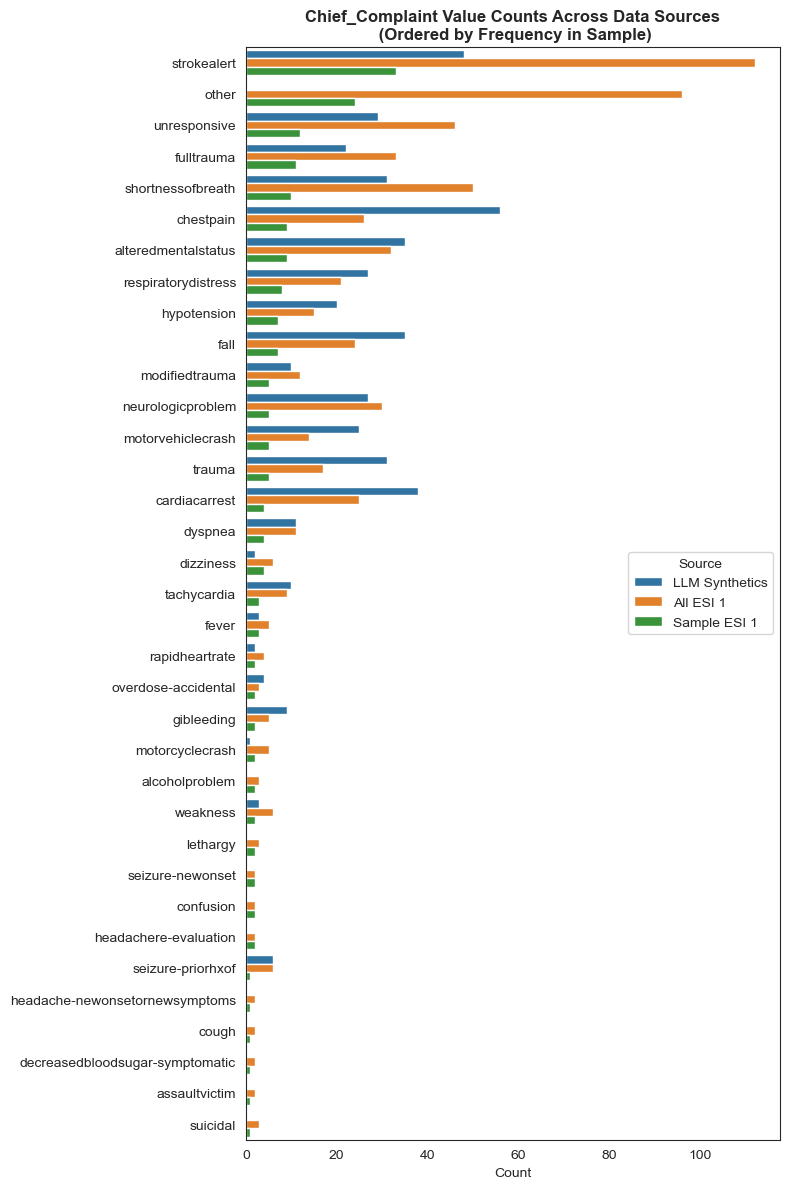

In [15]:
#Plotting a bar plot to compare counts across the 3 data sources

#melt replaces the wide dataframe with a long one
df_long = pd.melt(
    values_df,
    id_vars =['chief_complaint'],
    value_vars = ['LLM Synthetics','All ESI 1','Sample ESI 1'],
    var_name = 'data_source',
    value_name = 'value'
)

plt.figure(figsize=(8,12))
sns.set_style('white')

sns.barplot(data = df_long, y = 'chief_complaint', x ='value',hue = 'data_source')

plt.title('Chief_Complaint Value Counts Across Data Sources\n (Ordered by Frequency in Sample)', fontsize=12, fontweight='bold')
plt.xlabel('Count', fontsize=10)
plt.ylabel('')
plt.legend(title='Source', loc = 'right')
plt.tight_layout()


plt.show()

In [103]:
#Comparing the stats for patient vitals in both the orginal data and synthetic

vitals = ['triage_vital_hr','triage_vital_sbp',
                    'triage_vital_dbp','triage_vital_rr',
                    'triage_vital_o2','triage_vital_o2_device',
                    'triage_vital_temp'
                ]
X_train[vitals].describe()

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,274846.000000,274846.000000,274846.000000,274846.000000,274846.000000,274846.000000,274846.000000
mean,85.574131,133.395087,80.495509,17.617497,97.328295,0.034190,98.082268
std,16.690648,21.309249,13.858558,1.947452,1.726029,0.181717,0.772429
min,30.000000,45.000000,25.000000,8.000000,60.000000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,97.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,97.993408,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,98.176661,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,99.000000,1.000000,106.000000


In [104]:
X_train_synth[vitals].describe()

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,275346.000000,275346.000000,275346.000000,275346.000000,275346.000000,275346.000000,275346.000000
mean,85.646915,133.305409,80.426728,17.624445,97.308974,0.035661,98.081198
std,16.798463,21.418989,13.951728,2.027029,1.819326,0.185443,0.781013
min,30.000000,40.000000,20.000000,6.000000,51.500000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,97.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,97.989468,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,98.174831,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,100.000000,1.000000,106.000000


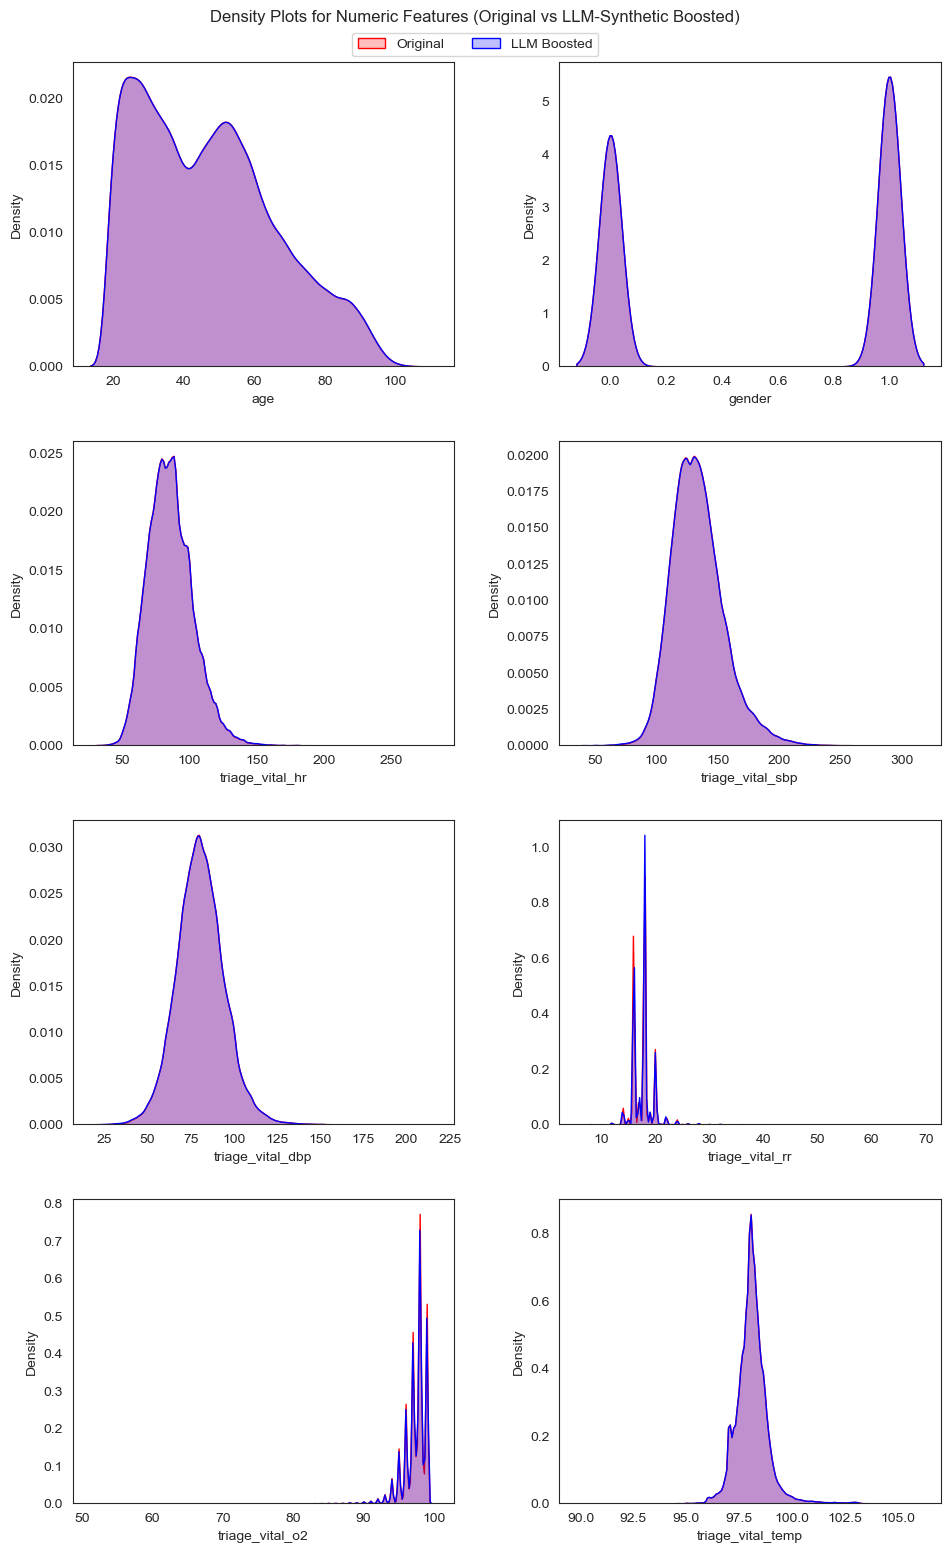

In [22]:
#Producing KDE plots for each vital to visualise differences between datasets

fig,axes = plt.subplots(4,2, figsize = (10,16))

sns.kdeplot(X_train['age'], color = 'r', fill = True, label = 'Original', ax = axes[0,0])
sns.kdeplot(X_train_synth['age'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[0,0])
sns.kdeplot(X_train['gender'], color = 'r', fill = True, label = 'Original', ax = axes[0,1])
sns.kdeplot(X_train_synth['gender'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[0,1])
sns.kdeplot(X_train['triage_vital_hr'], color = 'r', fill = True, label = 'Original', ax = axes[1,0])
sns.kdeplot(X_train_synth['triage_vital_hr'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[1,0])
sns.kdeplot(X_train['triage_vital_sbp'], color = 'r', fill = True, label = 'Original', ax = axes[1,1])
sns.kdeplot(X_train_synth['triage_vital_sbp'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[1,1])
sns.kdeplot(X_train['triage_vital_dbp'], color = 'r', fill = True, label = 'Original', ax = axes[2,0])
sns.kdeplot(X_train_synth['triage_vital_dbp'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[2,0])
sns.kdeplot(X_train['triage_vital_rr'], color = 'r', fill = True, label = 'Original', ax = axes[2,1])
sns.kdeplot(X_train_synth['triage_vital_rr'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[2,1])
sns.kdeplot(X_train['triage_vital_o2'], color = 'r', fill = True, label = 'Original', ax = axes[3,0])
sns.kdeplot(X_train_synth['triage_vital_o2'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[3,0])
sns.kdeplot(X_train['triage_vital_temp'], color = 'r', fill = True, label = 'Original', ax = axes[3,1])
sns.kdeplot(X_train_synth['triage_vital_temp'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[3,1])

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper center', 
           ncol = len(handles), bbox_to_anchor=(0.5, 0.97))
plt.suptitle("Density Plots for Numeric Features (Original vs LLM-Synthetic Boosted)")
plt.tight_layout(pad =2.5)
plt.show()

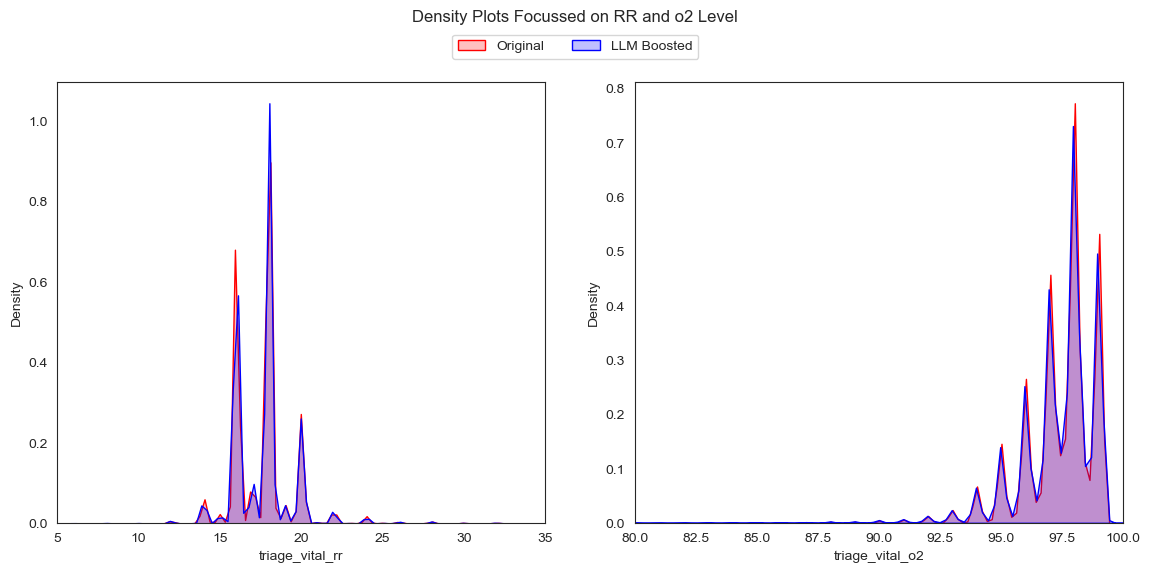

In [31]:
fig,axes = plt.subplots(1,2, figsize = (12,6))

sns.kdeplot(X_train['triage_vital_rr'], color = 'r', fill = True, label = 'Original', ax = axes[0])
sns.kdeplot(X_train_synth['triage_vital_rr'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[0])
sns.kdeplot(X_train['triage_vital_o2'], color = 'r', fill = True, label = 'Original', ax = axes[1])
sns.kdeplot(X_train_synth['triage_vital_o2'], color = 'b', fill = True, label = 'LLM Boosted', ax = axes[1])

#limiting the plots' x axes
axes[0].set_xlim(5,35)
axes[1].set_xlim(80,100)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper center', 
           ncol = len(handles), bbox_to_anchor=(0.5, 0.95))
plt.suptitle("Density Plots Focussed on RR and o2 Level")
plt.tight_layout(pad =2.5)
plt.show()

In [8]:
#Encoding target labels 
#replacing ESI codes 1-5 with integers 0-4
y_train_s = le.transform(y_train_synth)

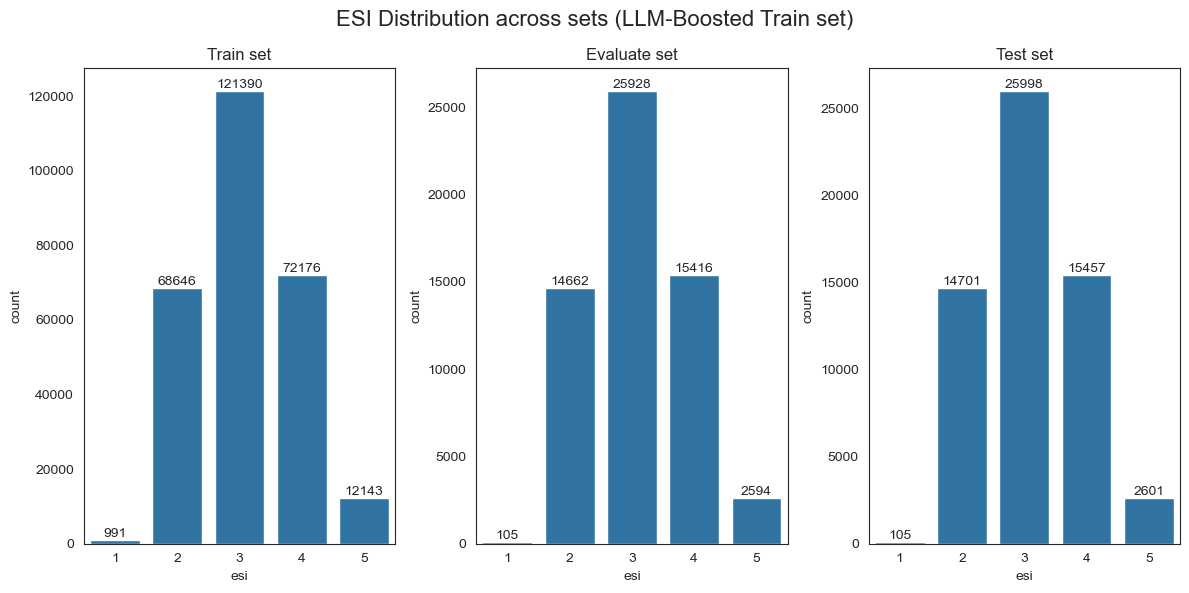

In [9]:
#Plotting histograms to show target feature distribution across sets
#evidence for correct stratification
#value counts added to show ESI level 1 instances.

fig, axes = plt.subplots(1,3, figsize = (12,6))
sns.set_style('white')
plot1 = axes[0]
plot2 = axes[1]
plot3 = axes[2]

chart1 = sns.countplot(x=y_train_synth, ax = plot1, order=[1,2,3,4,5])
plot1.set_title("Train set")
chart1.bar_label(chart1.containers[0]) #add value counts to bars

chart2 = sns.countplot(x=y_val, ax = plot2, order=[1,2,3,4,5])
plot2.set_title("Evaluate set")
chart2.bar_label(chart2.containers[0])

chart3 = sns.countplot(x=y_test, ax = plot3, order=[1,2,3,4,5])
plot3.set_title("Test set")
chart3.bar_label(chart3.containers[0])

plt.suptitle('ESI Distribution across sets (LLM-Boosted Train set)', fontsize = 16)
plt.tight_layout()
plt.show()

### Encoding Chief Complaint

In [35]:
#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train_synth.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train_synth[['chief_complaint']],y_train_s)

#Transform only for validate and test data
#blindly applies the mappings from training data to transform the val/test data
X_val_encoded['chief_complaint'] = encoder.transform(X_val[['chief_complaint']])
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])


In [36]:
#declaring label binariser globally
#all models in this section are trained on the same y_train_encoded
label_binarizer = LabelBinarizer().fit(y_train_encoded)

### Model Training

XGBoost produced the highest performance in initial model evaluation, so is used as the model for futher experiments

In [37]:
optimal_estimators = find_optimal_estimators(
    X = X_train_encoded,
    y=y_train_s,
    learning_rate=0.1
)

Running Cross-Validation with early stopping (LR = 0.1)

---- Early Stopping Results ----
Optimal n_estimators found: 573
Best CV Multi-LogLoss: 0.7110


In [38]:
#Running hyperparameter tuning function

#One Round of tuning using hyperparameter ranges based on Previous XGBoost Tuning
#num_iterations = 20

# xgb_structure_params = {
#      'xgb__max_depth': [4,5,6,7,8],
#      'xgb__min_child_weight': [3,4,5,6,7],
#      'xgb__subsample':[0.5,0.6,0.7,0.8,0.9],
#      'xgb__colsample_bytree':[0.4,0.5,0.6,0.7,0.8],
#      'xgb__reg_alpha':[0,1,2,3,4,5],
#      'xgb__reg_lambda':[0,1,3,5,7,9]
#  }

#Hyperparams for final model
xgb_structure_params = {
     'xgb__max_depth': [7],
     'xgb__min_child_weight': [4],
     'xgb__subsample':[0.9],
     'xgb__colsample_bytree':[0.6],
     'xgb__reg_alpha':[2],
     'xgb__reg_lambda':[7]
 }

tuned_xgb = tune_XGBoost(
    param_dist=xgb_structure_params,
    X = X_train_encoded,
    y = y_train_s,
    num_iterations=1,
    n_estimators=573, #taken from optimal estimators func
    learning_rate=0.1
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 1 candidates, totalling 5 fits

---- Results ----
Best Score (F1-macro): 0.6298
Best Hyperparameters:
 - xgb__subsample: 0.9
 - xgb__reg_lambda: 7
 - xgb__reg_alpha: 2
 - xgb__min_child_weight: 4
 - xgb__max_depth: 7
 - xgb__colsample_bytree: 0.6


In [39]:
#Producing and Applying optimal threshold weights
final_weights, val_probs = threshold_weighting(tuned_xgb,X_val_encoded,y_val_encoded,
                                               target_c1_recall=0.60)
#Specifying ESI 1 boosting to recall of 0.6

optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
xgb_LLMBoosted_preds = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 29.71
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 2.98


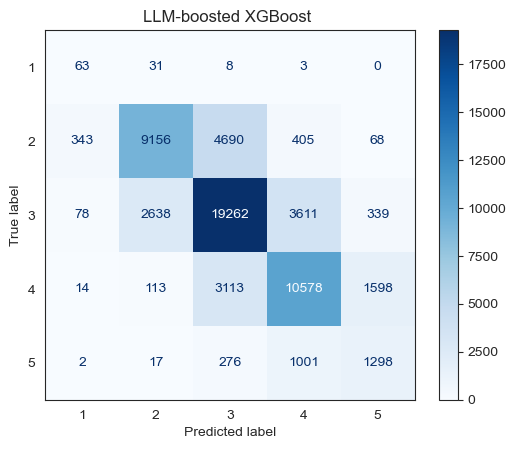

Classification Report:
               precision    recall  f1-score   support

           1       0.13      0.60      0.21       105
           2       0.77      0.62      0.69     14662
           3       0.70      0.74      0.72     25928
           4       0.68      0.69      0.68     15416
           5       0.39      0.50      0.44      2594

    accuracy                           0.69     58705
   macro avg       0.53      0.63      0.55     58705
weighted avg       0.70      0.69      0.69     58705



In [40]:
#Weighted Model evaluation

cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("LLM-boosted XGBoost ")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

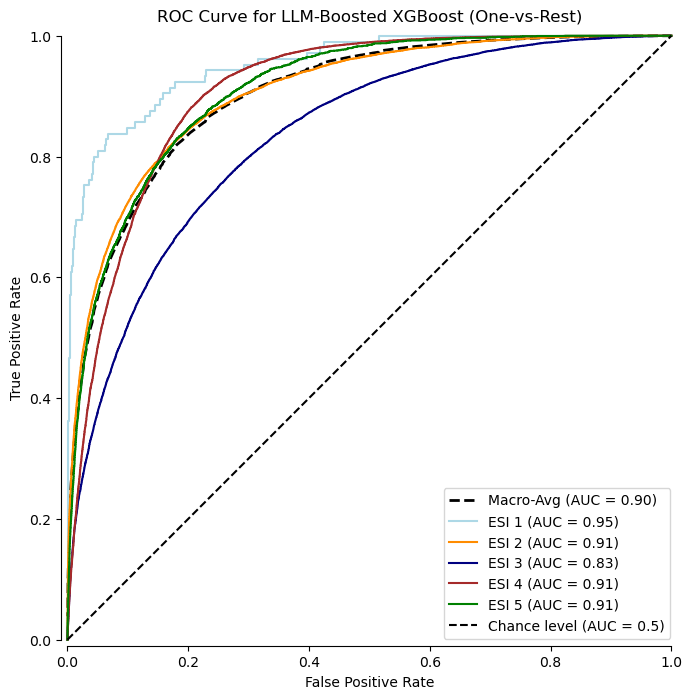

In [27]:
PlotROC_oneModel(
    modelName = 'LLM-Boosted XGBoost',
    y_test = y_val_encoded,
    y_score = xgb_LLMBoosted_preds
)

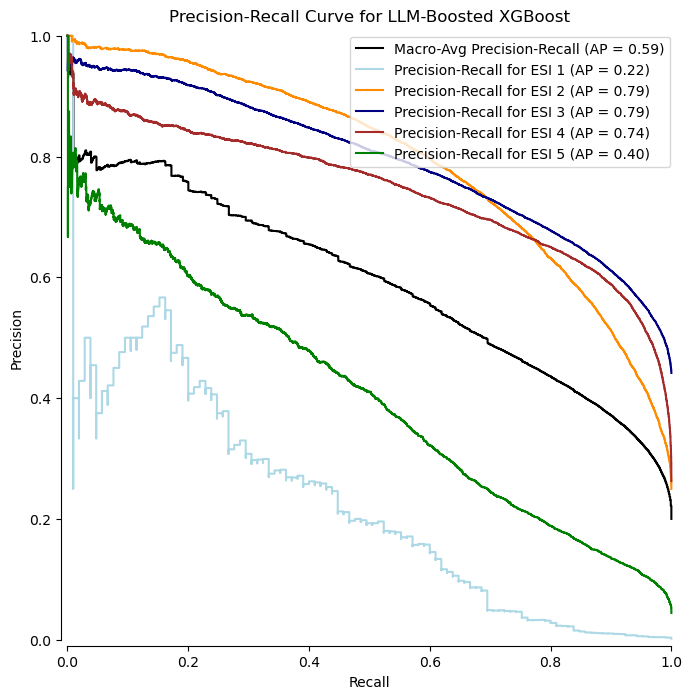

In [28]:
PlotPR_oneModel(
    modelName = 'LLM-Boosted XGBoost',
    y_test = y_val_encoded,
    y_score = xgb_LLMBoosted_preds
)

## 5. Experimenting with removal of PMH features

In [25]:
#Removing PMH cols
pmh_cols = triage_df.filter(like="pmh_")

triage_df = triage_df.drop(columns = pmh_cols)

In [26]:
#splitting into train test and evaluation sets

X = triage_df.drop(columns='esi')
y = triage_df['esi']

#Split 1 into combined train/eval and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

#Split 2: splitting train/eval into two sets
#eval size set to 0.176 (0.176 of 85% = 14.96% of total dataset)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.176, stratify=y_train_val, random_state=42
)

In [27]:
#Encoding target labels 
#replacing ESI codes 1-5 with integers 0-4
le = LabelEncoder()
le.fit(y_train)

y_train_encoded = le.transform(y_train)
y_val_encoded = le.transform(y_val)
y_test_encoded = le.transform(y_test)

### Experiment using Standard Dataset

In [28]:
#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train[['chief_complaint']],y_train_encoded)

#Transform only for validate and test data
#blindly applies the mappings from training data to transform the val/test data
X_val_encoded['chief_complaint'] = encoder.transform(X_val[['chief_complaint']])
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])


#defining labels for model evaluation metrics
esi_labels = ['1','2','3','4','5']

In [87]:
#Finding optimal number of estimators
optimal_estimators = find_optimal_estimators(
    X = X_train_encoded,
    y=y_train_encoded,
    learning_rate=0.1
)

Running Cross-Validation with early stopping (LR = 0.1)

---- Early Stopping Results ----
Optimal n_estimators found: 414
Best CV Multi-LogLoss: 0.7160


In [29]:
#Running hyperparameter tuning function

#Value ranges based on best performing XGBoost Tune
xgb_structure_params = {
    'xgb__max_depth': [5,6,7],
    'xgb__min_child_weight': [4,5,6],
    'xgb__subsample':[0.7,0.8,0.9],
    'xgb__colsample_bytree':[0.5,0.6,0.7],
    'xgb__reg_alpha':[0,1,2,3,4,5],
    'xgb__reg_lambda':[0,1,3,5,7,9]
}
tuned_xgb = tune_XGBoost(
    param_dist=xgb_structure_params,
    X = X_train_encoded,
    y = y_train_encoded,
    num_iterations=15,
    n_estimators=414, #taken from optimal estimators func
    learning_rate=0.1
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 15 candidates, totalling 75 fits

---- Results ----
Best Score (F1-macro): 0.5448
Best Hyperparameters:
 - xgb__subsample: 0.8
 - xgb__reg_lambda: 1
 - xgb__reg_alpha: 1
 - xgb__min_child_weight: 5
 - xgb__max_depth: 5
 - xgb__colsample_bytree: 0.5


In [30]:
#Finding threshold weights
final_weights, val_probs = threshold_weighting(tuned_xgb,X_val_encoded,y_val_encoded, target_c1_recall=0.60)

#applying threshold multipliers to predictions
optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
xgb_nonPMH_preds = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 23.27
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 2.98


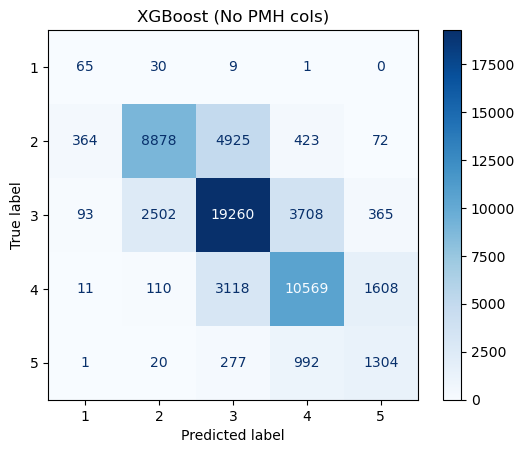

Classification Report:
               precision    recall  f1-score   support

           1       0.12      0.62      0.20       105
           2       0.77      0.61      0.68     14662
           3       0.70      0.74      0.72     25928
           4       0.67      0.69      0.68     15416
           5       0.39      0.50      0.44      2594

    accuracy                           0.68     58705
   macro avg       0.53      0.63      0.54     58705
weighted avg       0.69      0.68      0.69     58705



In [31]:
#Weighted Model evaluation 
cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("XGBoost (No PMH cols)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

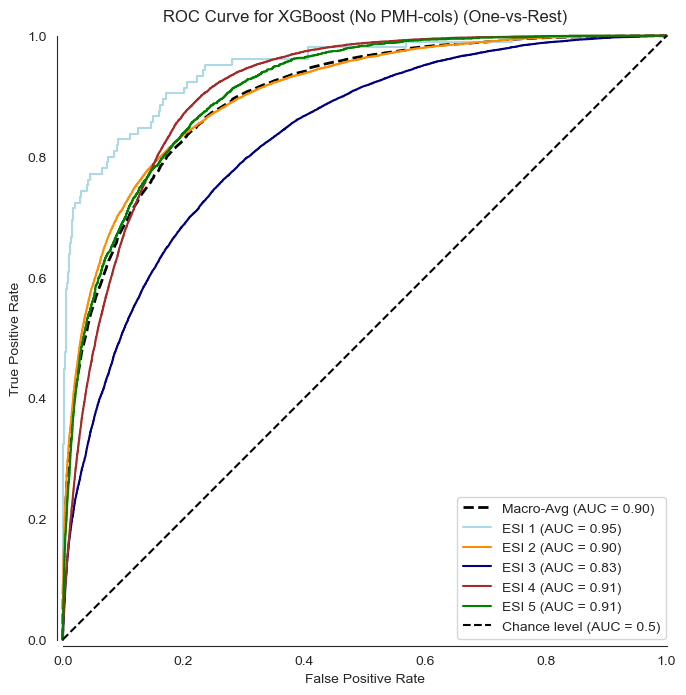

In [102]:
PlotROC_oneModel(
    modelName="XGBoost (No PMH-cols)",
    y_test = y_val_encoded,
    y_score = xgb_nonPMH_preds
)

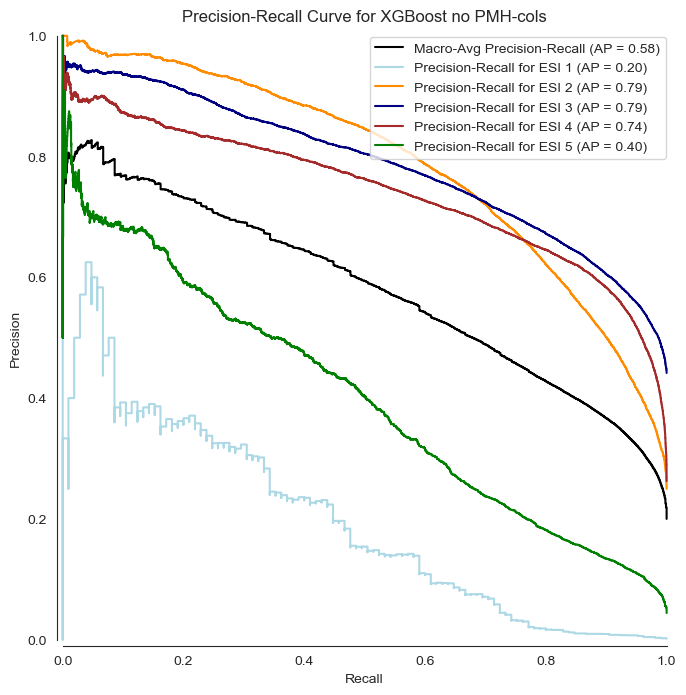

In [ ]:
PlotPR_oneModel(
    modelName = 'XGBoost no PMH-cols',
    y_test = y_val_encoded,
    y_score = xgb_nonPMH_preds
)

### Experiment using LLM-Boosted Dataset

In [103]:
#LLM output
LLM_synthetics_df = pd.read_csv('Data/LLM Synthetic Experiment/LLM Output MASTER.csv')

#removing pmh cols
LLM_synthetics_df = LLM_synthetics_df.drop(columns = pmh_cols)

#Splitting the synthetic set into X and y
X1 = LLM_synthetics_df.drop(columns = 'esi')
y1 = LLM_synthetics_df['esi']


#concatenating the synthetic values to the current train values
X_train_synth = pd.concat([X_train,X1])
y_train_synth = pd.concat([y_train,y1])

#ensure esi series converted to string
y_train_synth = y_train_synth.astype(str)

#Encoding target label
y_train_s = le.transform(y_train_synth)

In [104]:
#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train_synth.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train_synth[['chief_complaint']],y_train_s)

#Transform only for validate and test data
#blindly applies the mappings from training data to transform the val/test data
X_val_encoded['chief_complaint'] = encoder.transform(X_val[['chief_complaint']])
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])

In [94]:
#Finding optimal number of estimators
optimal_estimators = find_optimal_estimators(
    X = X_train_encoded,
    y=y_train_s,
    learning_rate=0.1
)

Running Cross-Validation with early stopping (LR = 0.1)

---- Early Stopping Results ----
Optimal n_estimators found: 428
Best CV Multi-LogLoss: 0.7143


In [ ]:
#Running hyperparameter tuning function

#Value ranges based on best performing XGBoost Tune
xgb_structure_params = {
    'xgb__max_depth': [5,6,7],
    'xgb__min_child_weight': [4,5,6],
    'xgb__subsample':[0.7,0.8,0.9],
    'xgb__colsample_bytree':[0.5,0.6,0.7],
    'xgb__reg_alpha':[0,1,2,3,4,5],
    'xgb__reg_lambda':[0,1,3,5,7,9]
}
tuned_xgb = tune_XGBoost(
    param_dist=xgb_structure_params,
    X = X_train_encoded,
    y = y_train_s,
    num_iterations=15,
    n_estimators=428, #taken from optimal estimators func
    learning_rate=0.1
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 15 candidates, totalling 75 fits

---- Results ----
Best Score (F1-macro): 0.6292
Best Hyperparameters:
 - xgb__subsample: 0.9
 - xgb__reg_lambda: 0
 - xgb__reg_alpha: 4
 - xgb__min_child_weight: 5
 - xgb__max_depth: 8
 - xgb__colsample_bytree: 0.4


In [ ]:
#Finding threshold weights
final_weights, val_probs = threshold_weighting(tuned_xgb,X_val_encoded,y_val_encoded,
                                               target_c1_recall=0.60)
#specifying 0.6 target recall ESI 1

#applying threshold multipliers to predictions
optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
xgb_nonPMH_LLMBoosted_preds = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 21.79
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 2.98


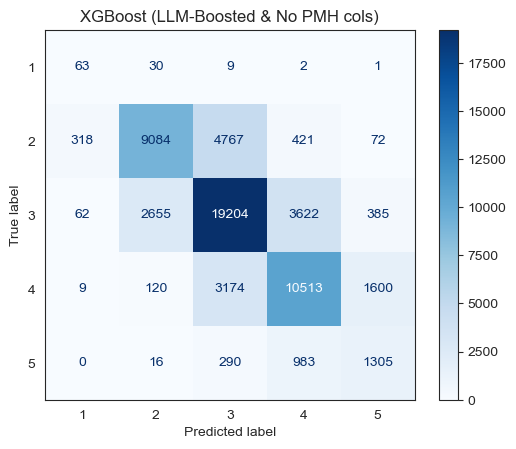

Classification Report:
               precision    recall  f1-score   support

           1       0.14      0.60      0.23       105
           2       0.76      0.62      0.68     14662
           3       0.70      0.74      0.72     25928
           4       0.68      0.68      0.68     15416
           5       0.39      0.50      0.44      2594

    accuracy                           0.68     58705
   macro avg       0.53      0.63      0.55     58705
weighted avg       0.69      0.68      0.69     58705



In [152]:
#Weighted LLM-boosted Model evaluation 
cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("XGBoost (LLM-Boosted & No PMH cols)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

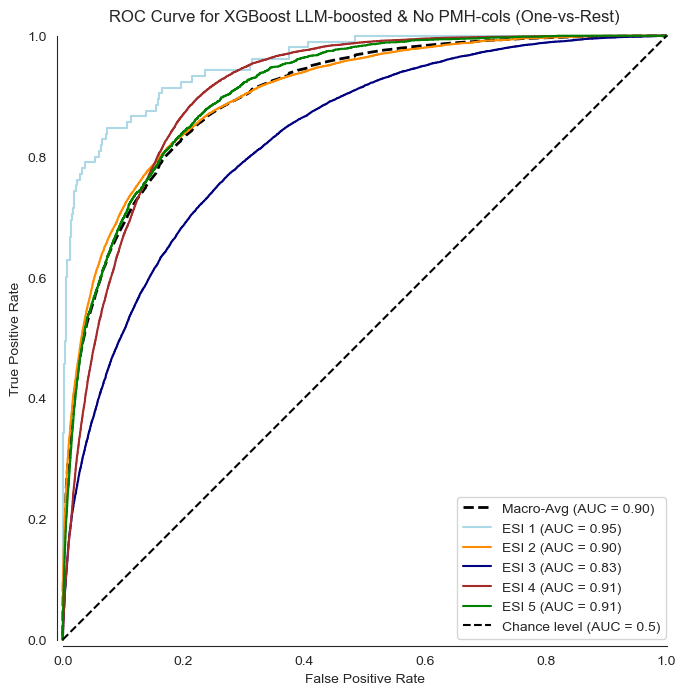

In [143]:
PlotROC_oneModel(
    modelName="XGBoost LLM-boosted & No PMH-cols",
    y_test = y_val_encoded,
    y_score = xgb_nonPMH_LLMBoosted_preds
)

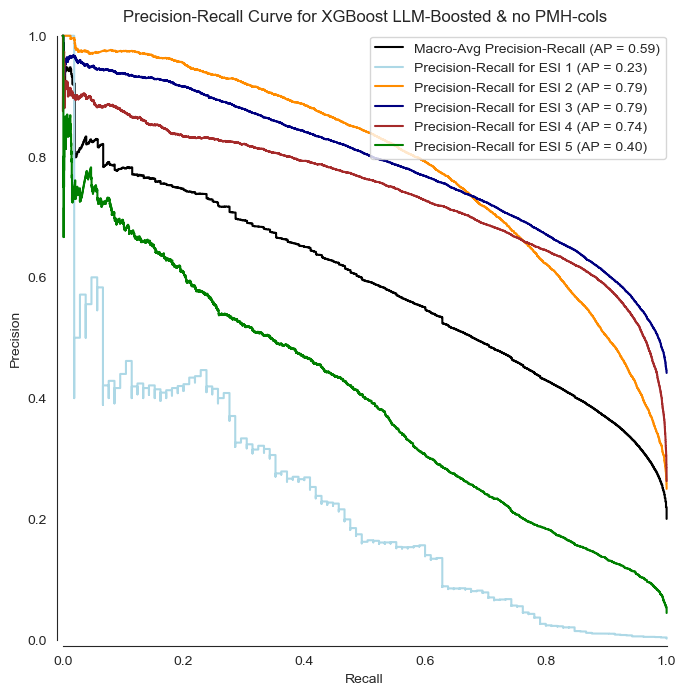

In [ ]:
PlotPR_oneModel(
    modelName = 'XGBoost LLM-Boosted & no PMH-cols',
    y_test = y_val_encoded,
    y_score = xgb_nonPMH_LLMBoosted_preds
)

## 6. Final Model Tuning and Training

This section reduces the learning rate of the best performing XGBoost version (the LLM-Boosted model) to improve model robustness. It is a repetition of most of section 4, with the one change to model hyperparameters

In [14]:
#Returning LLM output
#Outputted synthetic patient data based on the samples provided 

LLM_synthetics_df = pd.read_csv('Data/LLM Synthetic Experiment/LLM Output MASTER.csv')

#Splitting the synthetic set into X and y
X1 = LLM_synthetics_df.drop(columns = 'esi')
y1 = LLM_synthetics_df['esi']


#concatenating the synthetic values to the current train values
X_train_synth = pd.concat([X_train,X1])
y_train_synth = pd.concat([y_train,y1])

#ensure esi series is categorical
y_train_synth = y_train_synth.astype(str)

#Encoding target label
y_train_s = le.transform(y_train_synth)

In [25]:
label_binarizer = LabelBinarizer().fit(y_train_encoded)

In [15]:
#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train_synth.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train_synth[['chief_complaint']],y_train_s)

#Transform only for validate and test data
#blindly applies the mappings from training data to transform the val/test data
X_val_encoded['chief_complaint'] = encoder.transform(X_val[['chief_complaint']])
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])

In [16]:
optimal_estimators = find_optimal_estimators(
    X = X_train_encoded,
    y=y_train_s,
    learning_rate=0.02
)

Running Cross-Validation with early stopping (LR = 0.02)

---- Early Stopping Results ----
Optimal n_estimators found: 2781
Best CV Multi-LogLoss: 0.7105


In [17]:
#Hyperparams for final run through with lowered learning_rate
xgb_structure_params = {
     'xgb__max_depth': [7],
     'xgb__min_child_weight': [4],
     'xgb__subsample':[0.9],
     'xgb__colsample_bytree':[0.6],
     'xgb__reg_alpha':[2],
     'xgb__reg_lambda':[7]
 }

tuned_xgb = tune_XGBoost(
    param_dist=xgb_structure_params,
    X = X_train_encoded,
    y = y_train_s,
    num_iterations=1, #1 iteration for final hyperparams
    n_estimators=2781, #taken from optimal estimators func
    learning_rate=0.02
)

Starting Hyperparameter tuning
Fitting 5 folds for each of 1 candidates, totalling 5 fits

---- Results ----
Best Score (F1-macro): 0.6305
Best Hyperparameters:
 - xgb__subsample: 0.9
 - xgb__reg_lambda: 7
 - xgb__reg_alpha: 2
 - xgb__min_child_weight: 4
 - xgb__max_depth: 7
 - xgb__colsample_bytree: 0.6


In [18]:
#Producing and Applying optimal threshold weights
final_weights, val_probs = threshold_weighting(tuned_xgb,X_val_encoded,y_val_encoded,
                                               target_c1_recall=0.60)
#Specifying ESI 1 boosting to recall of 0.6

optimised_val_probs = val_probs * final_weights
optimised_preds = le.inverse_transform(np.argmax(optimised_val_probs, axis = 1))

#encoded preds proba (used for ROC-AUC curves):
xgb_LLMBoosted_preds = optimised_val_probs

--- final weight multipliers ---
Class 1 Multiplier: 26.74
Class 2 Multiplier: 1.00
Class 3 Multiplier: 1.00
Class 4 Multiplier: 1.00
Class 5 Multiplier: 2.98


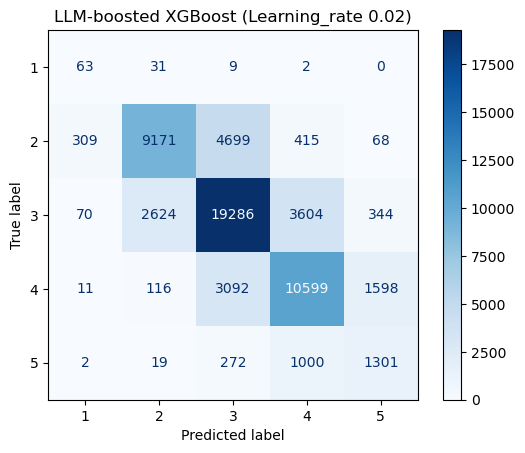

Classification Report:
               precision    recall  f1-score   support

           1       0.14      0.60      0.23       105
           2       0.77      0.63      0.69     14662
           3       0.70      0.74      0.72     25928
           4       0.68      0.69      0.68     15416
           5       0.39      0.50      0.44      2594

    accuracy                           0.69     58705
   macro avg       0.54      0.63      0.55     58705
weighted avg       0.70      0.69      0.69     58705



In [22]:
#Model Evaluation on eval set

cm = confusion_matrix(y_val,optimised_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("LLM-boosted XGBoost (Learning_rate 0.02)")
plt.show()

print("Classification Report:\n", classification_report(y_val,optimised_preds))

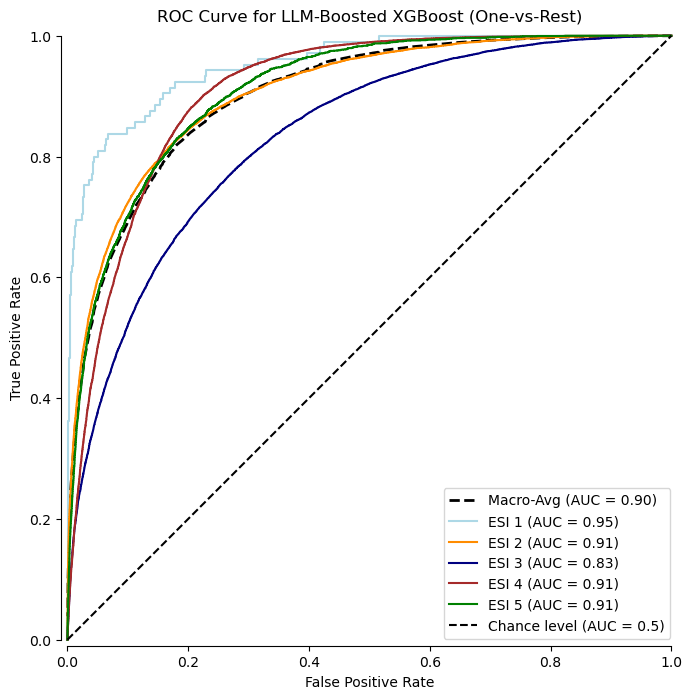

In [26]:
PlotROC_oneModel(
    modelName = 'LLM-Boosted XGBoost',
    y_test = y_val_encoded,
    y_score = xgb_LLMBoosted_preds
)

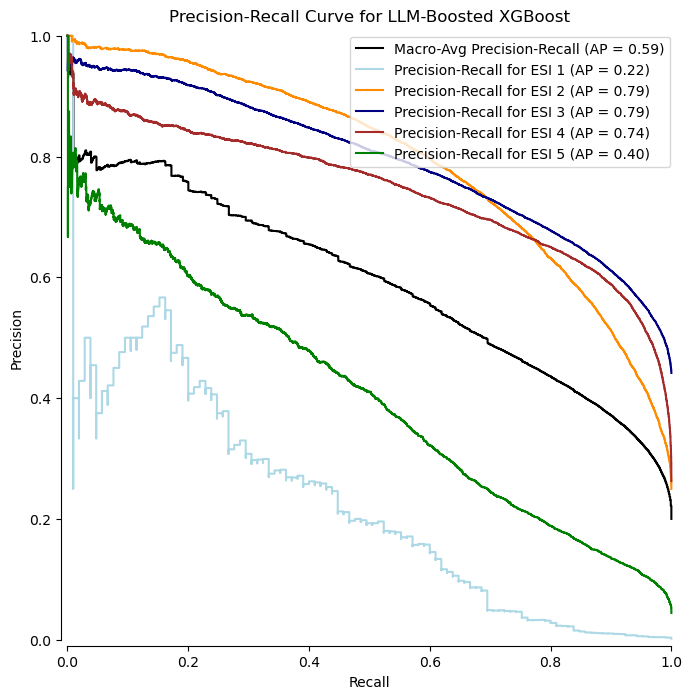

In [27]:
PlotPR_oneModel(
    modelName = 'LLM-Boosted XGBoost',
    y_test = y_val_encoded,
    y_score = xgb_LLMBoosted_preds
)